# Proyek Analisis Data: E-Commerce Customer Segmentation & RFM Analytics
- **Nama:** Ilfa Antaries Yusuf Wijaya
- **Email:** areswijaya.personal@gmail.com
- **ID Dicoding:** areswidjaja

## Menentukan Pertanyaan Bisnis

- Bagaimana distribusi **total penjualan** dan **jumlah transaksi** per kategori produk selama **12 bulan terakhir**, serta kategori mana yang memberikan **kontribusi pendapatan tertinggi**?

- Siapa saja **10 seller dengan nilai transaksi tertinggi** dan **jumlah pesanan terbanyak selama 6 bulan terakhir**, serta apakah terdapat **korelasi antara frekuensi penjualan** dan **rata-rata skor ulasan** yang diterima?

- Metode pembayaran dan jumlah cicilan apa yang paling **sering digunakan** serta menghasilkan **nilai transaksi tertinggi** selama **12 bulan terakhir**?

- Bagaimana distribusi **skor ulasan pelanggan** dan **durasi respons terhadap ulasan** per kategori produk selama **12 bulan terakhir**, serta kategori mana yang memiliki **tingkat kepuasan pelanggan tertinggi dan terendah**?

- Bagaimana tren **total penjualan** dan **jumlah pesanan** perusahaan per bulan selama **18 bulan terakhir**?

- Bagaimana segmentasi pelanggan berdasarkan analisis **RFM (Recency, Frequency, Monetary)**, segmen mana yang memberikan **kontribusi pendapatan terbesar**, dan apa **rekomendasi strategi bisnis** yang relevan untuk setiap segmen?

## Import Semua Packages/Library yang Digunakan

In [ ]:
# Import library analisis data
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Konfigurasi pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Konfigurasi seaborn
sns.set_theme(
    style='whitegrid',   # Tampilan grid bersih
    context='talk',  # Ukuran font & elemen clean
    palette='deep'       # Palet warna default yang konsisten
)

In [ ]:
import importlib

libs = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy']
for lib in libs:
    print(f"{lib}: {importlib.import_module(lib).__version__}")

pandas: 2.2.2
numpy: 2.0.2
matplotlib: 3.10.0
seaborn: 0.13.2
scipy: 1.16.3


## Data Wrangling

### Gathering Data

In [ ]:
# Customers
file_id = "12Lm4v_k3UZe9u4yFL6TaGv4X0JJ1MIXB"
dataset_url = f"https://drive.google.com/uc?id={file_id}"

customers_df = pd.read_csv(dataset_url)
print("Customers dataset:")
customers_df.head()

Customers dataset:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:
# Geolocation
file_id = "1Yt2CQ3fSRnWzDx8tndzRSiE0YyyePdxx"
dataset_url = f"https://drive.google.com/uc?id={file_id}"

geolocation_df = pd.read_csv(dataset_url)
print("Geolocation dataset:")
geolocation_df.head()

Geolocation dataset:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP
3,1041,-23.54,-46.64,sao paulo,SP
4,1035,-23.54,-46.64,sao paulo,SP


In [ ]:
# Order Items
file_id = "1ScRokdC2vPfRUEOTEz4d5qWU_Iw33wIR"
dataset_url = f"https://drive.google.com/uc?id={file_id}"

order_items_df = pd.read_csv(dataset_url)
print("Order Items dataset:")
order_items_df.head()

Order Items dataset:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
# Order Payments
file_id = "1ou7iqj_Jl97_t7Bohjk2XsE_ny65IOvD"
dataset_url = f"https://drive.google.com/uc?id={file_id}"

order_payments_df = pd.read_csv(dataset_url)
print("Order Payments dataset:")
order_payments_df.head()

Order Payments dataset:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [ ]:
# Order Reviews
file_id = "19nnj7w0H9mshTmYeK12m-PGDfefKP3If"
dataset_url = f"https://drive.google.com/uc?id={file_id}"

order_reviews_df = pd.read_csv(dataset_url)
print("Order Reviews dataset:")
order_reviews_df.head()

Order Reviews dataset:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [ ]:
# Orders
file_id = "1ft77QH7tuwtrkJCEvxg6LxKCbtryjTeM"
dataset_url = f"https://drive.google.com/uc?id={file_id}"
orders_df = pd.read_csv(dataset_url)

print("Orders dataset:")
orders_df.head()

Orders dataset:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
# Product Category Name Translation
file_id = "1-SLNZrToZCuXRzZPEgtyNjhUGggthjvG"
dataset_url = f"https://drive.google.com/uc?id={file_id}"

product_category_df = pd.read_csv(dataset_url)
print("Product Category dataset:")
product_category_df.head()

Product Category dataset:


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [ ]:
# Products
file_id = "1J9AkDXW2PxtBZPcNduL5u_8F8wOAlclr"
dataset_url = f"https://drive.google.com/uc?id={file_id}"

products_df = pd.read_csv(dataset_url)
print("Products dataset:")
products_df.head()

Products dataset:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,1000.00,30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.00,261.00,1.00,371.00,26.00,4.00,26.00
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.00,402.00,4.00,625.00,20.00,17.00,13.00


In [ ]:
# Sellers
file_id = "1ut-8c0iju3cowIUL8cy9CntQODQnJjTY"
dataset_url = f"https://drive.google.com/uc?id={file_id}"

sellers_df = pd.read_csv(dataset_url)
print("Sellers dataset:")
sellers_df.head()

Sellers dataset:


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


**INSIGHT:**

- Dataset terdiri dari **9 tabel utama** yang merepresentasikan keseluruhan proses bisnis e-commerce, mulai dari transaksi, produk, penjual, hingga ulasan pelanggan.

- Untuk menjawab **empat pertanyaan bisnis utama** terkait penjualan per kategori, performa penjual, metode pembayaran, dan kepuasan pelanggan, analisis difokuskan pada **7 dataset relevan** (orders, order_items, order_payments, order_reviews, products, product_category, dan sellers), tanpa melibatkan customers dan geolocation.

- Seluruh dataset memiliki **key relasional yang konsisten** (order_id, product_id, seller_id), sehingga proses join antar tabel dapat dilakukan dengan mudah.

- Struktur data yang saling terhubung memungkinkan analisis multidimensional terhadap performa bisnis e-commerce secara komprehensif.

### Assessing Data

**Order Items**

In [ ]:
# Menampilkan informasi umum dataset (tipe data, non-null count, dll)
order_items_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [ ]:
# Menampilkan ringkasan statistik untuk semua kolom, termasuk non-numerik
order_items_df.describe(include='all')

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
count,112650,112650.00,112650,112650,112650,112650.00,112650.00
unique,98666,NaN,32951,3095,93318,NaN,NaN
top,8272b63d03f5f79c56e9e4120aec44ef,NaN,aca2eb7d00ea1a7b8ebd4e68314663af,6560211a19b47992c3666cc44a7e94c0,2017-07-21 18:25:23,NaN,NaN
freq,21,NaN,527,2033,21,NaN,NaN
mean,NaN,1.20,NaN,NaN,NaN,120.65,19.99
std,NaN,0.71,NaN,NaN,NaN,183.63,15.81
min,NaN,1.00,NaN,NaN,NaN,0.85,0.00
25%,NaN,1.00,NaN,NaN,NaN,39.90,13.08
50%,NaN,1.00,NaN,NaN,NaN,74.99,16.26
75%,NaN,1.00,NaN,NaN,NaN,134.90,21.15


In [ ]:
# Mengecek jumlah baris duplikat dalam dataset
print("Jumlah duplikat:", order_items_df.duplicated().sum())

Jumlah duplikat: 0


In [ ]:
# Mengecek jumlah missing values per kolom
print("Jumlah missing values per kolom:\n", order_items_df.isna().sum())

Jumlah missing values per kolom:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


**Order Payments**

In [ ]:
# Menampilkan informasi umum dataset (tipe data, non-null count, dll)
order_payments_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [ ]:
# Menampilkan ringkasan statistik untuk semua kolom, termasuk non-numerik
order_payments_df.describe(include='all')

,order_id,payment_sequential,payment_type,payment_installments,payment_value
count,103886,103886.00,103886,103886.00,103886.00
unique,99440,NaN,5,NaN,NaN
top,fa65dad1b0e818e3ccc5cb0e39231352,NaN,credit_card,NaN,NaN
freq,29,NaN,76795,NaN,NaN
mean,NaN,1.09,NaN,2.85,154.10
std,NaN,0.71,NaN,2.69,217.49
min,NaN,1.00,NaN,0.00,0.00
25%,NaN,1.00,NaN,1.00,56.79
50%,NaN,1.00,NaN,1.00,100.00
75%,NaN,1.00,NaN,4.00,171.84


In [ ]:
# Mengecek jumlah baris duplikat dalam dataset
print("Jumlah duplikat:", order_payments_df.duplicated().sum())

Jumlah duplikat: 0


In [ ]:
# Mengecek jumlah missing values per kolom
print("Jumlah missing values per kolom:\n", order_payments_df.isna().sum())

Jumlah missing values per kolom:
 order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64


**Order Reviews**

In [ ]:
# Menampilkan informasi umum dataset (tipe data, non-null count, dll)
order_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [ ]:
# Menampilkan ringkasan statistik untuk semua kolom, termasuk non-numerik
order_reviews_df.describe(include='all')

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
count,99224,99224,99224.00,11568,40977,99224,99224
unique,98410,98673,NaN,4527,36159,636,98248
top,4548534449b1f572e357211b90724f1b,03c939fd7fd3b38f8485a0f95798f1f6,NaN,Recomendo,Muito bom,2017-12-19 00:00:00,2017-06-15 23:21:05
freq,3,3,NaN,423,230,463,4
mean,NaN,NaN,4.09,NaN,NaN,NaN,NaN
std,NaN,NaN,1.35,NaN,NaN,NaN,NaN
min,NaN,NaN,1.00,NaN,NaN,NaN,NaN
25%,NaN,NaN,4.00,NaN,NaN,NaN,NaN
50%,NaN,NaN,5.00,NaN,NaN,NaN,NaN
75%,NaN,NaN,5.00,NaN,NaN,NaN,NaN


In [ ]:
# Mengecek jumlah baris duplikat dalam dataset
print("Jumlah duplikat:", order_reviews_df.duplicated().sum())

Jumlah duplikat: 0


In [ ]:
# Mengecek jumlah missing values per kolom
print("Jumlah missing values per kolom:\n", order_reviews_df.isna().sum())

Jumlah missing values per kolom:
 review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


**Orders**

In [ ]:
# Menampilkan informasi umum dataset (tipe data, non-null count, dll)
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [ ]:
# Menampilkan ringkasan statistik untuk semua kolom, termasuk non-numerik
orders_df.describe(include='all')

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [ ]:
# Mengecek jumlah baris duplikat dalam dataset
print("Jumlah duplikat:", orders_df.duplicated().sum())

Jumlah duplikat: 0


In [ ]:
# Mengecek jumlah missing values per kolom
print("Jumlah missing values per kolom:\n", orders_df.isna().sum())

Jumlah missing values per kolom:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


**Product Category**

In [ ]:
# Menampilkan informasi umum dataset (tipe data, non-null count, dll)
product_category_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [ ]:
# Menampilkan ringkasan statistik untuk semua kolom, termasuk non-numerik
product_category_df.describe(include='all')

,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


In [ ]:
# Mengecek jumlah baris duplikat dalam dataset
print("Jumlah duplikat:", product_category_df.duplicated().sum())

Jumlah duplikat: 0


In [ ]:
# Mengecek jumlah missing values per kolom
print("Jumlah missing values per kolom:\n", product_category_df.isna().sum())

Jumlah missing values per kolom:
 product_category_name            0
product_category_name_english    0
dtype: int64


**Products**

In [ ]:
# Menampilkan informasi umum dataset (tipe data, non-null count, dll)
products_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [ ]:
# Menampilkan ringkasan statistik untuk semua kolom, termasuk non-numerik
products_df.describe(include='all')

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32951,32341,32341.00,32341.00,32341.00,32949.00,32949.00,32949.00,32949.00
unique,32951,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,106392145fca363410d287a815be6de4,cama_mesa_banho,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,48.48,771.50,2.19,2276.47,30.82,16.94,23.20
std,NaN,NaN,10.25,635.12,1.74,4282.04,16.91,13.64,12.08
min,NaN,NaN,5.00,4.00,1.00,0.00,7.00,2.00,6.00
25%,NaN,NaN,42.00,339.00,1.00,300.00,18.00,8.00,15.00
50%,NaN,NaN,51.00,595.00,1.00,700.00,25.00,13.00,20.00
75%,NaN,NaN,57.00,972.00,3.00,1900.00,38.00,21.00,30.00


In [ ]:
# Mengecek jumlah baris duplikat dalam dataset
print("Jumlah duplikat:", products_df.duplicated().sum())

Jumlah duplikat: 0


In [ ]:
# Mengecek jumlah missing values per kolom
print("Jumlah missing values per kolom:\n", products_df.isna().sum())

Jumlah missing values per kolom:
 product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


**Sellers**

In [ ]:
# Menampilkan informasi umum dataset (tipe data, non-null count, dll)
sellers_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [ ]:
# Menampilkan ringkasan statistik untuk semua kolom, termasuk non-numerik
sellers_df.describe(include='all')

,seller_id,seller_zip_code_prefix,seller_city,seller_state
count,3095,3095.00,3095,3095
unique,3095,NaN,611,23
top,9e25199f6ef7e7c347120ff175652c3b,NaN,sao paulo,SP
freq,1,NaN,694,1849
mean,NaN,32291.06,NaN,NaN
std,NaN,32713.45,NaN,NaN
min,NaN,1001.00,NaN,NaN
25%,NaN,7093.50,NaN,NaN
50%,NaN,14940.00,NaN,NaN
75%,NaN,64552.50,NaN,NaN


In [ ]:
# Mengecek jumlah baris duplikat dalam dataset
print("Jumlah duplikat:", sellers_df.duplicated().sum())

Jumlah duplikat: 0


In [ ]:
# Mengecek jumlah missing values per kolom
print("Jumlah missing values per kolom:\n", sellers_df.isna().sum())

Jumlah missing values per kolom:
 seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64


**INSIGHT**

- ***Order Items:*** Dataset tidak memiliki missing values maupun duplikasi, dengan struktur data yang konsisten. Kolom shipping_limit_date perlu dikonversi ke datetime. Nilai ekstrem pada price dan freight_value terdeteksi, namun masih realistis dalam konteks e-commerce dan mencerminkan variasi produk serta biaya kirim yang wajar.

- ***Order Payments:*** Dataset berisi 103.886 entri tanpa missing values dan sudah memiliki tipe data yang sesuai. Struktur data konsisten dengan hubungan one-to-many terhadap orders_df. Mayoritas pembayaran menggunakan credit_card dan dilakukan satu kali per pesanan. Ditemukan beberapa nilai ekstrem pada payment_sequential dan payment_value, namun masih logis dalam konteks e-commerce.

- ***Order Reviews:*** Dataset berisi 99.224 ulasan dengan beberapa duplikasi pada order_id. Sebagian besar pelanggan memberi skor tinggi (mean 4.09) dan tidak menulis komentar, yang umum pada e-commerce. Kolom waktu masih bertipe object dan perlu dikonversi ke datetime.

- ***Orders:*** Dataset berisi 99.441 entri unik tanpa duplikasi. Terdapat beberapa missing values pada kolom waktu seperti order_approved_at, order_delivered_carrier_date, dan order_delivered_customer_date, yang wajar karena mencerminkan pesanan gagal atau belum dikirim. Semua kolom waktu masih bertipe object dan perlu dikonversi ke datetime. Mayoritas pesanan berstatus delivered, menunjukkan konsistensi data yang baik.

- ***Product Category:*** Dataset berisi 71 pasangan nama kategori produk dalam bahasa Portugis dan Inggris tanpa missing values maupun duplikasi. Struktur data sederhana dan lengkap.

- ***Products:*** Dataset berisi 32.951 produk unik tanpa duplikasi. Ditemukan sekitar 610 produk tanpa kategori dan deskripsi, serta beberapa nilai berat bernilai nol. Distribusi ukuran fisik produk masih wajar dan semua kolom memiliki tipe data yang sesuai.

- ***Sellers:*** Dataset berisi 3.095 penjual unik tanpa missing values atau duplikasi. Semua kolom memiliki tipe data yang sesuai dan distribusi lokasi wajar, dengan mayoritas penjual berasal dari kota São Paulo.

### Cleaning Data

**Order Items**

In [ ]:
# 1. Cek ulang struktur dan tipe data
print("=== Informasi Dataset ===")
order_items_df.info()

print("\n=== Statistik Deskriptif ===")
display(order_items_df.describe(include='all'))

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB

=== Statistik Deskriptif ===


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
count,112650,112650.00,112650,112650,112650,112650.00,112650.00
unique,98666,NaN,32951,3095,93318,NaN,NaN
top,8272b63d03f5f79c56e9e4120aec44ef,NaN,aca2eb7d00ea1a7b8ebd4e68314663af,6560211a19b47992c3666cc44a7e94c0,2017-07-21 18:25:23,NaN,NaN
freq,21,NaN,527,2033,21,NaN,NaN
mean,NaN,1.20,NaN,NaN,NaN,120.65,19.99
std,NaN,0.71,NaN,NaN,NaN,183.63,15.81
min,NaN,1.00,NaN,NaN,NaN,0.85,0.00
25%,NaN,1.00,NaN,NaN,NaN,39.90,13.08
50%,NaN,1.00,NaN,NaN,NaN,74.99,16.26
75%,NaN,1.00,NaN,NaN,NaN,134.90,21.15


In [ ]:
# 2. Konversi kolom tanggal ke datetime
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'], errors='coerce')

# 3. Hapus duplikasi jika ada (berdasarkan kombinasi unik order_id + order_item_id)
order_items_df.drop_duplicates(subset=['order_id', 'order_item_id'], inplace=True)

# 4. Validasi nilai numerik (tidak boleh negatif atau nol tidak logis)
invalid_price = order_items_df[order_items_df['price'] <= 0]
invalid_freight = order_items_df[order_items_df['freight_value'] < 0]

print(f"Invalid price count: {len(invalid_price)}")
print(f"Invalid freight count: {len(invalid_freight)}")

Invalid price count: 0
Invalid freight count: 0


In [ ]:
# 5. Tambahkan flag analisis
order_items_df['is_price_outlier'] = order_items_df['price'] > 3000   # produk premium
order_items_df['is_free_freight'] = order_items_df['freight_value'] == 0  # promo atau free shipping

# 6. Cek kembali data setelah cleaning
print("=== Kondisi Dataset Setelah Cleaning ===")
print("Data shape:", order_payments_df.shape)
print("\nMissing values per column:")
print(order_items_df.isna().sum())

# 7. Pastikan kombinasi kunci unik (sanity check)
dupes = order_items_df.duplicated(subset=['order_id', 'order_item_id']).sum()
print(f"\nDuplicate rows after cleaning: {dupes}")

=== Kondisi Dataset Setelah Cleaning ===
Data shape: (103886, 5)

Missing values per column:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
is_price_outlier       0
is_free_freight        0
dtype: int64

Duplicate rows after cleaning: 0


**Order Payments**

In [ ]:
# 1. Cek ulang struktur dan tipe data
print("=== Informasi Dataset ===")
order_payments_df.info()

print("\n=== Statistik Deskriptif ===")
display(order_payments_df.describe(include='all'))

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB

=== Statistik Deskriptif ===


,order_id,payment_sequential,payment_type,payment_installments,payment_value
count,103886,103886.00,103886,103886.00,103886.00
unique,99440,NaN,5,NaN,NaN
top,fa65dad1b0e818e3ccc5cb0e39231352,NaN,credit_card,NaN,NaN
freq,29,NaN,76795,NaN,NaN
mean,NaN,1.09,NaN,2.85,154.10
std,NaN,0.71,NaN,2.69,217.49
min,NaN,1.00,NaN,0.00,0.00
25%,NaN,1.00,NaN,1.00,56.79
50%,NaN,1.00,NaN,1.00,100.00
75%,NaN,1.00,NaN,4.00,171.84


In [ ]:
# 2. Hapus duplikasi jika ada (berdasarkan kombinasi unik order_id + payment_sequential)
order_payments_df.drop_duplicates(subset=['order_id', 'payment_sequential'], inplace=True)

# 3. Normalisasi nilai kategori payment_type
order_payments_df['payment_type'] = order_payments_df['payment_type'].replace('not_defined', 'unknown')

# 4. Flag untuk pembayaran tidak wajar
order_payments_df['is_seq_outlier'] = order_payments_df['payment_sequential'] > 10
order_payments_df['is_zero_payment'] = order_payments_df['payment_value'] == 0

# 5. Validasi nilai negatif
invalid_payment = order_payments_df[order_payments_df['payment_value'] < 0]
print(f"Invalid payment count: {len(invalid_payment)}")

Invalid payment count: 0


In [ ]:
# 7. Cek kembali kondisi dataset setelah cleaning
print("=== Kondisi Dataset Setelah Cleaning ===")
print("Data shape:", order_payments_df.shape)
print("\nMissing values per column:")
print(order_payments_df.isna().sum())

# 8. Pastikan kombinasi kunci unik
dupes = order_payments_df.duplicated(subset=['order_id', 'payment_sequential']).sum()
print(f"\nDuplicate rows after cleaning: {dupes}")

=== Kondisi Dataset Setelah Cleaning ===
Data shape: (103886, 7)

Missing values per column:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
is_seq_outlier          0
is_zero_payment         0
dtype: int64

Duplicate rows after cleaning: 0


**Order Reviews**

In [ ]:
# 1. Cek ulang struktur dan tipe data
print("=== Informasi Dataset ===")
order_reviews_df.info()

print("\n=== Statistik Deskriptif ===")
display(order_reviews_df.describe(include='all'))

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB

=== Statistik Deskriptif ===


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
count,99224,99224,99224.00,11568,40977,99224,99224
unique,98410,98673,NaN,4527,36159,636,98248
top,4548534449b1f572e357211b90724f1b,03c939fd7fd3b38f8485a0f95798f1f6,NaN,Recomendo,Muito bom,2017-12-19 00:00:00,2017-06-15 23:21:05
freq,3,3,NaN,423,230,463,4
mean,NaN,NaN,4.09,NaN,NaN,NaN,NaN
std,NaN,NaN,1.35,NaN,NaN,NaN,NaN
min,NaN,NaN,1.00,NaN,NaN,NaN,NaN
25%,NaN,NaN,4.00,NaN,NaN,NaN,NaN
50%,NaN,NaN,5.00,NaN,NaN,NaN,NaN
75%,NaN,NaN,5.00,NaN,NaN,NaN,NaN


In [ ]:
# 2. Konversi kolom waktu ke datetime
date_cols = ['review_creation_date', 'review_answer_timestamp']
for col in date_cols:
    order_reviews_df[col] = pd.to_datetime(order_reviews_df[col], errors='coerce')

# 3. Hapus duplikasi berdasarkan order_id (ambil review terakhir)
order_reviews_df.sort_values('review_answer_timestamp', inplace=True)
order_reviews_df.drop_duplicates(subset='order_id', keep='last', inplace=True)

# 4. Validasi logika waktu
invalid_time = order_reviews_df[
    order_reviews_df['review_answer_timestamp'] < order_reviews_df['review_creation_date']
]
print(f"Jumlah review dengan waktu tidak logis: {len(invalid_time)}")

Jumlah review dengan waktu tidak logis: 0


In [ ]:
# 5. Cek missing values (biarkan karena bermakna)
print("Missing values per column:")
display(order_reviews_df.isna().sum())

# 6. Pastikan kombinasi kunci unik
dupes = order_reviews_df.duplicated(subset=['order_id']).sum()
print(f"\nDuplicate order_id after cleaning: {dupes}")

Missing values per column:


,0
review_id,0
order_id,0
review_score,0
review_comment_title,87123
review_comment_message,57898
review_creation_date,0
review_answer_timestamp,0



Duplicate order_id after cleaning: 0


**Orders**

In [ ]:
# 1. Cek ulang struktur dan tipe data
print("=== Informasi Dataset ===")
orders_df.info()

print("\n=== Statistik Deskriptif ===")
display(orders_df.describe(include='all'))

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

=== Statistik Deskriptif ===


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [ ]:
# 2. Konversi seluruh kolom waktu ke datetime
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col], errors='coerce')

print("=== Konversi Kolom Waktu Selesai ===")
display(orders_df[date_cols].dtypes)

# 3. Pastikan urutan waktu logis
invalid_order_time = orders_df[
    (orders_df['order_delivered_customer_date'] < orders_df['order_purchase_timestamp'])
]
print(f"\nJumlah order dengan tanggal tidak logis: {len(invalid_order_time)}")

invalid_estimate = orders_df[
    orders_df['order_estimated_delivery_date'] < orders_df['order_purchase_timestamp']
]
print(f"Jumlah order dengan estimasi tidak logis: {len(invalid_estimate)}")

=== Konversi Kolom Waktu Selesai ===


,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]



Jumlah order dengan tanggal tidak logis: 0
Jumlah order dengan estimasi tidak logis: 0


In [ ]:
# 4. Flag order terkirim dan dibatalkan
orders_df['is_delivered'] = orders_df['order_status'] == 'delivered'
orders_df['is_canceled'] = orders_df['order_status'].isin(['canceled', 'unavailable'])

# 5. Cek rasio pengiriman dan pembatalan
delivery_rate = orders_df['is_delivered'].mean() * 100
cancel_rate = orders_df['is_canceled'].mean() * 100

print(f"Tingkat keberhasilan pengiriman: {delivery_rate:.2f}%")
print(f"Tingkat pembatalan pesanan: {cancel_rate:.2f}%")

Tingkat keberhasilan pengiriman: 97.02%
Tingkat pembatalan pesanan: 1.24%


In [ ]:
# 6. Cek kembali kondisi dataset setelah cleaning
print("=== Kondisi Dataset Setelah Cleaning ===")
print("Data shape:", orders_df.shape)
print("\nMissing values per column:")
print(orders_df.isna().sum())

# 7. Pastikan tidak ada duplikasi order_id
dupes = orders_df.duplicated(subset=['order_id']).sum()
print(f"\nDuplicate rows after cleaning: {dupes}")

=== Kondisi Dataset Setelah Cleaning ===
Data shape: (99441, 10)

Missing values per column:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
is_delivered                        0
is_canceled                         0
dtype: int64

Duplicate rows after cleaning: 0


**Product Category**

In [ ]:
# 1. Cek ulang struktur dan tipe data
print("=== Informasi Dataset ===")
product_category_df.info()

print("\n=== Statistik Deskriptif ===")
display(product_category_df.describe(include='all'))

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB

=== Statistik Deskriptif ===


,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


In [ ]:
# 2. Pastikan tidak ada duplikasi
dupes = product_category_df.duplicated(subset=['product_category_name']).sum()
print(f"Duplicate rows: {dupes}")

# 3. Normalisasi nama kategori (lowercase + strip whitespace)
product_category_df['product_category_name'] = product_category_df['product_category_name'].str.strip().str.lower()
product_category_df['product_category_name_english'] = product_category_df['product_category_name_english'].str.strip().str.lower()

Duplicate rows: 0


**Products**

In [ ]:
# 1. Cek ulang struktur dan tipe data
print("=== Informasi Dataset ===")
products_df.info()

print("\n=== Statistik Deskriptif ===")
display(products_df.describe(include='all'))

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB

=== Statistik Deskriptif ===


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32951,32341,32341.00,32341.00,32341.00,32949.00,32949.00,32949.00,32949.00
unique,32951,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,106392145fca363410d287a815be6de4,cama_mesa_banho,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,48.48,771.50,2.19,2276.47,30.82,16.94,23.20
std,NaN,NaN,10.25,635.12,1.74,4282.04,16.91,13.64,12.08
min,NaN,NaN,5.00,4.00,1.00,0.00,7.00,2.00,6.00
25%,NaN,NaN,42.00,339.00,1.00,300.00,18.00,8.00,15.00
50%,NaN,NaN,51.00,595.00,1.00,700.00,25.00,13.00,20.00
75%,NaN,NaN,57.00,972.00,3.00,1900.00,38.00,21.00,30.00


In [ ]:
# 2. Hapus duplikasi jika ada (berdasarkan product_id)
products_df.drop_duplicates(subset=['product_id'], inplace=True)

# 3. Flag untuk nilai anomali berat produk (0 gram)
products_df['is_weight_zero'] = products_df['product_weight_g'] == 0

# 4. Cek missing values
print("Missing values per column:")
display(products_df.isna().sum())

# 5. Normalisasi nama kategori (lowercase + strip)
products_df['product_category_name'] = products_df['product_category_name'].str.strip().str.lower()

# 6. Cek distribusi nilai ekstrem berat produk
outliers_weight = products_df[products_df['product_weight_g'] > 20000]
print(f"\nProduk dengan berat > 20 kg: {len(outliers_weight)}")


Missing values per column:


,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2
is_weight_zero,0



Produk dengan berat > 20 kg: 485


**Sellers**

In [ ]:
# 1. Cek ulang struktur dan tipe data
print("=== Informasi ===")
sellers_df.info()

print("\n=== Statistik ===")
display(sellers_df.describe(include='all'))

=== Informasi ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB

=== Statistik ===


,seller_id,seller_zip_code_prefix,seller_city,seller_state
count,3095,3095.00,3095,3095
unique,3095,NaN,611,23
top,9e25199f6ef7e7c347120ff175652c3b,NaN,sao paulo,SP
freq,1,NaN,694,1849
mean,NaN,32291.06,NaN,NaN
std,NaN,32713.45,NaN,NaN
min,NaN,1001.00,NaN,NaN
25%,NaN,7093.50,NaN,NaN
50%,NaN,14940.00,NaN,NaN
75%,NaN,64552.50,NaN,NaN


In [ ]:
# 2. Pastikan tidak ada duplikasi
dupes = sellers_df.duplicated(subset=['seller_id']).sum()
print(f"Duplicate seller_id: {dupes}")

# 3. Normalisasi nama kota & provinsi (lowercase + strip whitespace)
sellers_df['seller_city'] = sellers_df['seller_city'].str.strip().str.lower()
sellers_df['seller_state'] = sellers_df['seller_state'].str.strip().str.upper()

Duplicate seller_id: 0


**INSIGHT:**

- ***Order Items:*** Setelah konversi shipping_limit_date ke datetime dan verifikasi keunikan kombinasi order_id–order_item_id, dataset dinyatakan bersih dan siap dianalisis. Tidak ditemukan nilai negatif atau tidak logis. Nilai ekstrem dipertahankan karena masih relevan secara bisnis, dengan distribusi price dan freight_value yang right-skewed khas transaksi e-commerce.

- ***Order Payments:*** Tidak ditemukan duplikasi atau nilai negatif. Nilai kategori payment_type telah dinormalisasi dengan mengganti not_defined menjadi unknown. Kolom flag ditambahkan untuk menandai pembayaran ekstrem (payment_sequential > 10) dan transaksi bernilai nol. Seluruh data dinyatakan valid dan siap digunakan untuk tahap EDA, khususnya analisis metode pembayaran, jumlah cicilan, serta kontribusi nilai transaksi per pesanan.

- ***Order Reviews:*** Kolom waktu telah dikonversi ke datetime, dan duplikasi berdasarkan order_id dihapus dengan mempertahankan ulasan terbaru. Nilai review_score valid dalam rentang 1–5, dan missing pada kolom teks dipertahankan karena bermakna. Dataset dinyatakan bersih dan siap untuk EDA, terutama analisis distribusi skor dan durasi respons terhadap ulasan.

- ***Orders:*** Seluruh kolom waktu telah dikonversi ke datetime dan urutan kronologis diverifikasi tanpa anomali berarti. Tidak ditemukan duplikasi, dan dua flag tambahan (is_delivered, is_canceled) dibuat untuk analisis status pesanan. Missing values dibiarkan karena bermakna secara bisnis. Dataset dinyatakan bersih dan siap untuk tahap EDA, dengan tingkat keberhasilan pengiriman sekitar 97% dan pembatalan di bawah 3%.

- ***Product Category:*** Normalisasi huruf kecil dilakukan untuk menjaga konsistensi penamaan sebelum proses join. Dataset dinyatakan bersih dan siap digunakan sebagai referensi kategori produk pada tabel products.

- ***Products:*** Duplikasi dihapus dan nama kategori dinormalisasi menjadi huruf kecil. Produk dengan berat nol diberi flag khusus untuk analisis lebih lanjut. Tidak dilakukan imputasi pada nilai missing karena bersifat informatif. Dataset dinyatakan bersih dan siap digunakan untuk EDA serta penggabungan dengan product_category_name_translation.

- ***Sellers:*** Nama kota dan kode provinsi dinormalisasi untuk menjaga konsistensi penulisan. Dataset dinyatakan bersih dan siap digunakan untuk analisis penjual serta integrasi dengan tabel order_items.

## Exploratory Data Analysis (EDA)

### Q1 Exploratory Data Analysis

**Pertanyaan:**

*Bagaimana distribusi total penjualan dan jumlah transaksi per kategori produk selama 12 bulan terakhir, serta kategori mana yang memberikan kontribusi pendapatan tertinggi?*

**Tujuan EDA:**
1. Menggabungkan dataset yang relevan (orders, order_items, products, product_category_name_translation).
2. Menyaring data hanya untuk order berstatus delivered dalam 12 bulan terakhir.
3. Menghitung metrik dasar: Total pendapatan (revenue) per kategori, jumlah transaksi per kategori.
4. Menyusun data agregasi untuk keperluan visualisasi dan explanatory nanti.



**Distribusi Total Penjualan per Kategori**

In [ ]:
# 1. Filter hanya order dengan status 'delivered'
delivered_orders = orders_df[orders_df['order_status'] == 'delivered']

# 2. Ambil data 12 bulan terakhir dari tanggal maksimum pembelian
latest_date = delivered_orders['order_purchase_timestamp'].max()
one_year_ago = latest_date - pd.DateOffset(months=12)

recent_orders = delivered_orders[
    delivered_orders['order_purchase_timestamp'] >= one_year_ago
]

print(f"Periode data: {one_year_ago.date()} hingga {latest_date.date()}")
print(f"Jumlah order (delivered) dalam 12 bulan terakhir: {recent_orders.shape[0]}")

# 3. Gabungkan tabel order, order_items, dan produk
merged_df = (
    recent_orders
    .merge(order_items_df, on='order_id', how='inner')
    .merge(products_df[['product_id', 'product_category_name']], on='product_id', how='left')
    .merge(product_category_df, on='product_category_name', how='left')
)

# 4. Hitung total pendapatan per item
merged_df['revenue'] = merged_df['price'] + merged_df['freight_value']

# 5. Agregasi per kategori produk
sales_by_category = (
    merged_df.groupby('product_category_name_english', as_index=False)
    .agg({
        'revenue': 'sum',
        'order_id': 'nunique'
    })
    .rename(columns={
        'revenue': 'total_revenue',
        'order_id': 'total_transactions'
    })
    .sort_values(by='total_revenue', ascending=False)
)

# 6. Ambil 10 kategori teratas
top10_sales = sales_by_category.nlargest(10, 'total_revenue')
top10_transactions = sales_by_category.nlargest(10, 'total_transactions')

Periode data: 2017-08-29 hingga 2018-08-29
Jumlah order (delivered) dalam 12 bulan terakhir: 74605


In [ ]:
# 7. Tampilkan hasil agregasi
print("Top 10 kategori berdasarkan Total Revenue:")
display(top10_sales)

print("\nTop 10 kategori berdasarkan Total Transactions:")
display(top10_transactions)

print("\nStatistik ringkas kolom numerik:")
display(sales_by_category[['total_revenue', 'total_transactions']].describe())

Top 10 kategori berdasarkan Total Revenue:


,product_category_name_english,total_revenue,total_transactions
43,health_beauty,1134382.47,6963
70,watches_gifts,1050878.84,4731
7,bed_bath_table,930061.42,7052
65,sports_leisure,863064.62,5797
15,computers_accessories,790901.08,5140
39,furniture_decor,663634.52,4546
49,housewares,603953.66,4369
5,auto,526629.04,3137
20,cool_stuff,460299.58,2361
69,toys,407423.51,2786



Top 10 kategori berdasarkan Total Transactions:


,product_category_name_english,total_revenue,total_transactions
7,bed_bath_table,930061.42,7052
43,health_beauty,1134382.47,6963
65,sports_leisure,863064.62,5797
15,computers_accessories,790901.08,5140
70,watches_gifts,1050878.84,4731
39,furniture_decor,663634.52,4546
49,housewares,603953.66,4369
5,auto,526629.04,3137
68,telephony,305926.11,3087
69,toys,407423.51,2786



Statistik ringkas kolom numerik:


,total_revenue,total_transactions
count,71.00,71.00
mean,166631.95,1045.65
std,267511.58,1726.62
min,115.45,1.00
25%,7697.29,61.00
50%,42938.22,199.00
75%,179505.08,1073.00
max,1134382.47,7052.00


**INSIGHT:**

Selama 12 bulan terakhir, kategori health_beauty, watches_gifts, dan bed_bath_table menjadi penyumbang pendapatan terbesar perusahaan, masing-masing dengan total pendapatan sekitar 1,13 juta BRL, 1,05 juta BRL, dan 930 ribu BRL. Dari sisi jumlah transaksi, bed_bath_table mencatat volume tertinggi (7.052 transaksi), diikuti health_beauty (6.963) dan sports_leisure (5.797).

Rata-rata penjualan per kategori mencapai 166 ribu BRL dengan sekitar 1.046 transaksi, sementara pendapatan tertinggi mencapai 1,13 juta BRL, menunjukkan adanya kesenjangan yang besar antara kategori unggulan dan kategori dengan kontribusi kecil. Pola ini menegaskan bahwa sebagian besar pendapatan perusahaan terpusat pada beberapa kategori utama, terutama produk kebutuhan rumah tangga dan personal care yang memiliki permintaan tinggi serta pembelian berulang.

**INSIGHT:**

- ***Visualisasi 1 | Top 10 Kategori Berdasarkan Total Revenue (12 Bulan Terakhir)***: Kategori health_beauty menempati posisi teratas sebagai penyumbang pendapatan tertinggi selama 12 bulan terakhir, diikuti oleh watches_gifts dan bed_bath_table.
Kategori dengan nilai transaksi besar seperti health_beauty dan computers_accessories menunjukkan rata-rata nilai pembelian yang tinggi per order, menandakan produk bernilai tinggi dan berkontribusi besar terhadap total revenue meskipun tidak memiliki volume transaksi sebanyak kategori lain. Sementara itu, kategori seperti sports_leisure dan furniture_decor tetap memberikan kontribusi signifikan namun lebih moderat, menandakan pasar yang stabil namun tidak terlalu dominan.

- ***Visualisasi 2 | Top 10 Kategori Berdasarkan Jumlah Transaksi (12 Bulan Terakhir):*** Kategori bed_bath_table dan health_beauty mendominasi jumlah transaksi, menandakan tingkat permintaan konsumen yang tinggi dan berulang. Kategori seperti sports_leisure, computers_accessories, dan watches_gifts juga memiliki volume transaksi besar, menunjukkan minat konsumen terhadap produk gaya hidup dan teknologi. Namun, kategori seperti furniture_decor dan auto memiliki transaksi lebih sedikit meskipun bernilai tinggi, menggambarkan produk dengan harga tinggi dan frekuensi pembelian rendah. Pola ini memperlihatkan bahwa perusahaan mengandalkan kombinasi produk cepat laku dengan margin kecil dan produk premium dengan margin besar untuk menjaga stabilitas pendapatan.

- ***Visualisasi 3 | Tren Penjualan Bulanan per Kategori (12 Bulan Terakhir)***: Tren penjualan bulanan menunjukkan bahwa kategori health_beauty dan bed_bath_table memiliki stabilitas penjualan yang konsisten sepanjang tahun, mengindikasikan permintaan rutin yang tidak terpengaruh musim. Sebaliknya, watches_gifts mengalami lonjakan penjualan tajam pada November–Desember, kemungkinan besar karena periode liburan dan pemberian hadiah. Kategori computers_accessories mengalami peningkatan pada awal tahun, sejalan dengan periode back-to-work atau back-to-school. Sementara sports_leisure menunjukkan fluktuasi yang ringan, menandakan pasar aktif namun tidak terikat musim tertentu.

Selama 12 bulan terakhir, Olist berhasil mempertahankan performa penjualan tertinggi pada kategori health_beauty, bed_bath_table, dan computers_accessories. Kategori kebutuhan rumah tangga dan personal care memberikan kontribusi stabil terhadap pendapatan, sedangkan kategori seperti watches_gifts dan toys menawarkan peluang besar melalui strategi promosi musiman. Kombinasi antara produk rutin dan musiman menjadikan struktur penjualan Olist seimbang antara stabilitas dan pertumbuhan.

### Q2 Exploratory Data Analysis

**Pertanyaan:**

*Siapa saja 10 seller dengan nilai transaksi tertinggi dan jumlah pesanan terbanyak selama 6 bulan terakhir, serta apakah terdapat korelasi antara frekuensi penjualan dan rata-rata skor ulasan yang diterima?*

**Tujuan EDA:**
1. Menyaring order berstatus delivered dalam 6 bulan terakhir.
2. Menggabungkan dataset yang relevan (orders, order_items, order_reviews, sellers).
3. Menghitung metrik utama per penjual: Total revenue (nilai transaksi), Total orders (jumlah pesanan unik), dan Rata-rata skor review.
4. Menampilkan Top 10 seller berdasarkan total_revenue dan total_orders.
5. Menghitung korelasi numerik antara frekuensi penjualan dan rata-rata skor ulasan.


In [ ]:
# 1. Filter hanya order dengan status 'delivered'
delivered_orders = orders_df[orders_df['order_status'] == 'delivered']

# 2. Ambil data 6 bulan terakhir dari tanggal maksimum pembelian
latest_date = delivered_orders['order_purchase_timestamp'].max()
six_months_ago = latest_date - pd.DateOffset(months=6)

recent_orders = delivered_orders[
    delivered_orders['order_purchase_timestamp'] >= six_months_ago
]

print(f"Periode data: {six_months_ago.date()} hingga {latest_date.date()}")
print(f"Jumlah order (delivered) dalam 6 bulan terakhir: {recent_orders.shape[0]}")

# 3. Gabungkan tabel orders, order_items, dan order_reviews
seller_df = (
    recent_orders
    .merge(order_items_df, on='order_id', how='inner')
    .merge(order_reviews_df[['order_id', 'review_score']], on='order_id', how='left')
)

# 4. Hitung metrik utama per penjual
seller_summary = (
    seller_df.groupby('seller_id', as_index=False)
    .agg({
        'price': 'sum',
        'freight_value': 'sum',
        'order_id': 'nunique',
        'review_score': 'mean'
    })
    .rename(columns={
        'price': 'total_price',
        'freight_value': 'total_freight',
        'order_id': 'total_orders',
        'review_score': 'avg_review_score'
    })
)

# 5. Hitung total revenue per seller
seller_summary['total_revenue'] = seller_summary['total_price'] + seller_summary['total_freight']

# 6. Ambil 10 seller teratas berdasarkan total_revenue
top10_revenue = seller_summary.nlargest(10, 'total_revenue')

# 7. Hitung korelasi antara total_orders dan avg_review_score
correlation = seller_summary['total_orders'].corr(seller_summary['avg_review_score'])

Periode data: 2018-02-28 hingga 2018-08-29
Jumlah order (delivered) dalam 6 bulan terakhir: 39324


In [ ]:
# 8. Tampilkan hasil EDA
print("Top 10 seller berdasarkan Total Revenue:")
display(top10_revenue)

print(f"\nKorelasi antara frekuensi penjualan dan rata-rata skor ulasan: {correlation:.3f}")

print("\nStatistik ringkas metrik numerik per seller:")
display(seller_summary[['total_revenue', 'total_orders', 'avg_review_score']].describe())

Top 10 seller berdasarkan Total Revenue:


,seller_id,total_price,total_freight,total_orders,avg_review_score,total_revenue
143,1025f0e2d44d7041d6cf58b6550e0bfa,92485.01,22506.59,607,3.95,114991.60
1086,7d13fca15225358621be4086e1eb0964,107139.61,7817.23,535,4.07,114956.84
617,4869f7a5dfa277a7dca6462dcf3b52b2,98210.80,9890.51,559,4.18,108101.31
1284,955fee9216a65b617aa5c0531780ce60,89058.52,14627.26,773,4.07,103685.78
1083,7c67e1448b00f6e969d365cea6b010ab,65987.73,19979.44,344,3.37,85967.17
2112,fa1c13f2614d7b5c4749cbc52fecda94,68539.39,4296.78,223,4.23,72836.17
1858,da8622b14eb17ae2831f4ac5b9dab84a,59485.17,9542.40,519,4.18,69027.57
878,6560211a19b47992c3666cc44a7e94c0,54916.00,12718.89,803,3.93,67634.89
635,4a3ca9315b744ce9f8e9374361493884,49169.91,10446.28,470,3.92,59616.19
1377,a1043bafd471dff536d0c462352beb48,37249.21,12698.63,279,4.36,49947.84



Korelasi antara frekuensi penjualan dan rata-rata skor ulasan: -0.029

Statistik ringkas metrik numerik per seller:


,total_revenue,total_orders,avg_review_score
count,2158.00,2158.00,2156.00
mean,2983.15,18.54,4.19
std,7870.84,49.84,0.81
min,15.90,1.00,1.00
25%,278.94,2.00,3.94
50%,880.49,6.00,4.33
75%,2499.11,15.00,4.78
max,114991.60,803.00,5.00


**INSIGHT:**

Selama 6 bulan terakhir, penjual dengan nilai transaksi tertinggi adalah seller 1025f0e2d44d7041d6cf58b6550e0bfa, dengan total pendapatan sekitar 114.991 BRL dari 607 pesanan dan rata-rata skor ulasan 3,95. Diikuti oleh seller 7d13fca15225358621be4086e1eb0964 (114.956 BRL) dan seller 4869f7a5dfa277a7dca6462dcf3b52b2 (108.101 BRL).
Sementara itu, dari sisi jumlah pesanan, seller 6560211a19b47992c3666cc44a7e94c0 menempati posisi teratas dengan 803 pesanan, diikuti oleh seller 955fee9216a65b617aa5c0531780ce60 (773 pesanan) dan seller 1025f0e2d44d7041d6cf58b6550e0bfa (607 pesanan).

Secara keseluruhan, rata-rata penjual mencatat pendapatan sekitar 2.983 BRL dengan 18 pesanan, menunjukkan disparitas besar antara penjual top dan mayoritas penjual lainnya.
Nilai korelasi antara frekuensi penjualan dan skor ulasan rata-rata sebesar -0,029, menandakan hubungan yang sangat lemah dan hampir netral. Dengan kata lain, penjual yang memiliki volume transaksi tinggi tidak selalu memperoleh skor ulasan lebih rendah atau lebih tinggi, sehingga tingkat kepuasan pelanggan relatif stabil di seluruh penjual.

### Q3 Exploratory Data Analysis

**Pertanyaan:**

*Metode pembayaran dan jumlah cicilan apa yang paling sering digunakan serta menghasilkan nilai transaksi tertinggi selama 12 bulan terakhir?*

**Tujuan EDA:**
1. Menyaring transaksi selama 12 bulan terakhir dari orders_df (status delivered).
2. Menggabungkan dataset orders dan order_payments.
3. Menganalisis distribusi: Frekuensi penggunaan tiap metode pembayaran (payment_type), Jumlah cicilan (payment_installments), dan Nilai total transaksi (payment_value).
4. Mengidentifikasi: Metode pembayaran paling sering digunakan,
Jumlah cicilan yang paling umum, dan Kombinasi pembayaran-cicilan yang memberikan pendapatan tertinggi.


In [ ]:
# 1. Filter hanya order dengan status 'delivered'
delivered_orders = orders_df[orders_df['order_status'] == 'delivered']

# 2. Ambil data 12 bulan terakhir berdasarkan tanggal pembelian
latest_date = delivered_orders['order_purchase_timestamp'].max()
one_year_ago = latest_date - pd.DateOffset(months=12)

recent_orders = delivered_orders[
    delivered_orders['order_purchase_timestamp'] >= one_year_ago
]

print(f"Periode data: {one_year_ago.date()} hingga {latest_date.date()}")
print(f"Jumlah order (delivered) dalam 12 bulan terakhir: {recent_orders.shape[0]}")

# 3. Gabungkan dengan tabel pembayaran
payments_df = recent_orders.merge(order_payments_df, on='order_id', how='inner')

# 4. Hitung frekuensi metode pembayaran dan total nilai transaksi
payment_summary = (
    payments_df.groupby('payment_type', as_index=False)
    .agg({
        'order_id': 'nunique',
        'payment_value': 'sum'
    })
    .rename(columns={
        'order_id': 'total_orders',
        'payment_value': 'total_payment_value'
    })
    .sort_values(by='total_payment_value', ascending=False)
)

# 5. Analisis jumlah cicilan
installment_summary = (
    payments_df.groupby('payment_installments', as_index=False)
    .agg({
        'order_id': 'nunique',
        'payment_value': 'sum'
    })
    .rename(columns={
        'order_id': 'total_orders',
        'payment_value': 'total_payment_value'
    })
    .sort_values(by='total_orders', ascending=False)
)

# 6. Analisis kombinasi metode pembayaran dan jumlah cicilan
combo_summary = (
    payments_df.groupby(['payment_type', 'payment_installments'], as_index=False)
    .agg({
        'order_id': 'nunique',
        'payment_value': 'sum'
    })
    .rename(columns={
        'order_id': 'total_orders',
        'payment_value': 'total_payment_value'
    })
    .sort_values(by='total_payment_value', ascending=False)
)

Periode data: 2017-08-29 hingga 2018-08-29
Jumlah order (delivered) dalam 12 bulan terakhir: 74605


In [ ]:
# 7. Tampilkan hasil EDA
print("Top metode pembayaran berdasarkan total nilai transaksi:")
display(payment_summary.head(10))

print("\nJumlah cicilan yang paling sering digunakan:")
display(installment_summary.head(10))

print("\nKombinasi metode pembayaran dan cicilan dengan nilai transaksi tertinggi:")
display(combo_summary.head(10))

Top metode pembayaran berdasarkan total nilai transaksi:


,payment_type,total_orders,total_payment_value
1,credit_card,57722,9449574.95
0,boleto,14490,2085547.69
3,voucher,2675,254048.04
2,debit_card,1302,189915.09



Jumlah cicilan yang paling sering digunakan:


,payment_installments,total_orders,total_payment_value
1,1,37465,4457358.71
2,2,9524,1245756.41
3,3,7738,1134590.69
4,4,5209,877954.02
5,5,3784,711719.27
10,10,3532,1491947.51
8,8,3311,1037362.58
6,6,2839,619687.42
7,7,1140,218753.63
9,9,400,86027.40



Kombinasi metode pembayaran dan cicilan dengan nilai transaksi tertinggi:


,payment_type,payment_installments,total_orders,total_payment_value
0,boleto,1,14490,2085547.69
2,credit_card,1,20087,1927847.89
11,credit_card,10,3532,1491947.51
3,credit_card,2,9524,1245756.41
4,credit_card,3,7738,1134590.69
9,credit_card,8,3311,1037362.58
5,credit_card,4,5209,877954.02
6,credit_card,5,3784,711719.27
7,credit_card,6,2839,619687.42
26,voucher,1,2675,254048.04


In [ ]:
# 8. Statistik ringkas numerik
print("\nStatistik ringkas nilai pembayaran:")
display(payments_df[['payment_value', 'payment_installments']].describe())


Statistik ringkas nilai pembayaran:


,payment_value,payment_installments
count,77551.00,77551.00
mean,154.47,2.79
std,213.29,2.64
min,0.00,0.00
25%,57.68,1.00
50%,101.25,1.00
75%,173.25,4.00
max,13664.08,24.00


**INSIGHT:**

Selama 12 bulan terakhir, metode pembayaran credit_card menjadi pilihan dominan pelanggan dengan 57.722 transaksi dan total nilai pembayaran mencapai sekitar 9,45 juta BRL, disusul oleh boleto dengan 14.490 transaksi senilai 2,08 juta BRL. Metode lain seperti voucher dan debit_card hanya memberikan kontribusi kecil terhadap total transaksi perusahaan.

Dari sisi cicilan, pembayaran 1 kali (tanpa cicilan) paling banyak digunakan, yaitu 37.465 transaksi dengan total nilai sekitar 4,46 juta BRL. Meskipun sebagian besar pelanggan memilih pembayaran penuh, opsi cicilan 2–3 kali juga cukup populer dengan kontribusi nilai transaksi di atas 1 juta BRL masing-masing.

Kombinasi metode dan jumlah cicilan menunjukkan bahwa credit_card dengan 1–3 kali cicilan mendominasi nilai transaksi tertinggi, diikuti oleh credit_card dengan 10 kali cicilan untuk pembelian bernilai besar. Sementara itu, boleto dengan 1 kali pembayaran tetap menjadi metode alternatif penting untuk transaksi tunai langsung.

Secara keseluruhan, hasil EDA menunjukkan bahwa perusahaan sangat bergantung pada transaksi berbasis kartu kredit sebagai pendorong utama pendapatan, dengan preferensi konsumen yang cenderung memilih pembayaran langsung atau cicilan pendek dibandingkan skema cicilan panjang.

### Q4 Exploratory Data Analysis

**Pertanyaan:**

*Bagaimana distribusi skor ulasan pelanggan dan durasi respons terhadap ulasan per kategori produk selama 12 bulan terakhir, serta kategori mana yang memiliki tingkat kepuasan tertinggi dan terendah?*

**Tujuan EDA:**
1. Menyaring data 12 bulan terakhir hanya untuk pesanan berstatus delivered.
2. Menggabungkan tabel: orders, order_reviews, order_items, products, dan product_category_name_translation.
3. Menghitung: Rata-rata skor ulasan (review_score) per kategori, Rata-rata durasi respon terhadap ulasan (response_time = review_answer_timestamp - review_creation_date), Jumlah ulasan per kategori.
4. Menyusun tabel agregat kategori untuk digunakan di tahap visualisasi/explanatory berikutnya.


In [ ]:
# 1. Filter hanya order delivered
delivered_orders = orders_df[orders_df['order_status'] == 'delivered']

# 2. Ambil data 12 bulan terakhir
latest_date = delivered_orders['order_purchase_timestamp'].max()
one_year_ago = latest_date - pd.DateOffset(months=12)

recent_orders = delivered_orders[
    delivered_orders['order_purchase_timestamp'] >= one_year_ago
]

print(f"Periode data: {one_year_ago.date()} hingga {latest_date.date()}")
print(f"Jumlah order (delivered) dalam 12 bulan terakhir: {recent_orders.shape[0]}")

# 3. Gabungkan tabel review dengan kategori produk
review_df = (
    recent_orders
    .merge(order_reviews_df, on='order_id', how='inner')
    .merge(order_items_df[['order_id', 'product_id']], on='order_id', how='left')
    .merge(products_df[['product_id', 'product_category_name']], on='product_id', how='left')
    .merge(product_category_df, on='product_category_name', how='left')
)

# 4. Konversi kolom waktu ke datetime (jaga-jaga jika belum)
review_df['review_creation_date'] = pd.to_datetime(review_df['review_creation_date'])
review_df['review_answer_timestamp'] = pd.to_datetime(review_df['review_answer_timestamp'])

# 5. Hitung durasi respon (dalam jam)
review_df['response_time_hours'] = (
    (review_df['review_answer_timestamp'] - review_df['review_creation_date'])
    .dt.total_seconds() / 3600
)

# 6. Agregasi per kategori produk
review_summary = (
    review_df.groupby('product_category_name_english', as_index=False)
    .agg({
        'review_score': ['mean', 'count'],
        'response_time_hours': 'mean'
    })
)

# 7. Rapikan nama kolom
review_summary.columns = [
    'product_category_name_english',
    'avg_review_score',
    'total_reviews',
    'avg_response_time_hours'
]

# 8. Urutkan berdasarkan skor rata-rata tertinggi dan terendah
top_categories = review_summary.sort_values(by='avg_review_score', ascending=False).head(10)
bottom_categories = review_summary.sort_values(by='avg_review_score', ascending=True).head(10)

Periode data: 2017-08-29 hingga 2018-08-29
Jumlah order (delivered) dalam 12 bulan terakhir: 74605


In [ ]:
# 9. Tampilkan hasil
print("Top 10 kategori dengan skor ulasan tertinggi:")
display(top_categories)

print("\nTop 10 kategori dengan skor ulasan terendah:")
display(bottom_categories)

print("\nStatistik ringkas metrik numerik:")
display(review_summary[['avg_review_score', 'avg_response_time_hours', 'total_reviews']].describe())

Top 10 kategori dengan skor ulasan tertinggi:


,product_category_name_english,avg_review_score,total_reviews,avg_response_time_hours
11,cds_dvds_musicals,5.00,6,71.14
29,fashion_childrens_clothes,5.00,5,66.85
9,books_imported,4.55,53,66.37
8,books_general_interest,4.48,413,71.61
64,small_appliances_home_oven_and_coffee,4.45,71,63.97
22,costruction_tools_tools,4.43,96,62.80
35,flowers,4.42,31,58.97
10,books_technical,4.36,244,65.63
25,dvds_blu_ray,4.31,35,69.19
37,food_drink,4.31,226,52.46



Top 10 kategori dengan skor ulasan terendah:


,product_category_name_english,avg_review_score,total_reviews,avg_response_time_hours
61,security_and_services,1.00,1,44.83
46,home_comfort_2,3.11,18,58.60
52,la_cuisine,3.20,5,79.01
23,diapers_and_hygiene,3.33,36,91.58
57,office_furniture,3.42,1177,87.81
34,fixed_telephony,3.53,129,96.86
30,fashion_male_clothing,3.68,66,50.05
58,party_supplies,3.80,41,55.77
4,audio,3.82,286,65.41
40,furniture_living_room,3.84,328,70.78



Statistik ringkas metrik numerik:


,avg_review_score,avg_response_time_hours,total_reviews
count,71.00,71.00,71.00
mean,4.04,78.10,1178.73
std,0.48,55.55,1965.87
min,1.00,44.83,1.00
25%,3.97,65.50,68.50
50%,4.09,70.08,227.00
75%,4.22,78.77,1301.50
max,5.00,528.94,8337.00


**INSIGHT:**

Selama 12 bulan terakhir, tingkat kepuasan pelanggan perusahaan tergolong tinggi dengan rata-rata skor ulasan sebesar 4,04 dari 5. Beberapa kategori menunjukkan performa sempurna, di antaranya cds_dvds_musicals dan fashion_childrens_clothes yang sama-sama memperoleh skor rata-rata 5,00, diikuti oleh books_imported (4,55) dan books_general_interest (4,48).
Kategori-kategori tersebut umumnya memiliki volume ulasan kecil hingga menengah dan rata-rata waktu respons antara 60–70 jam, menandakan layanan yang cepat dan pengalaman pelanggan yang positif.

Sebaliknya, kategori dengan skor ulasan terendah adalah security_and_services (1,00), home_comfort_2 (3,11), dan office_furniture (3,42). Beberapa kategori seperti diapers_and_hygiene dan fixed_telephony juga mencatat skor di bawah rata-rata, mengindikasikan permasalahan kualitas produk atau proses pengiriman.
Menariknya, kategori dengan volume ulasan besar seperti office_furniture memiliki skor rendah namun rata-rata waktu respons tinggi (sekitar 88 jam), menunjukkan potensi beban layanan pelanggan atau keterlambatan tanggapan.

Secara keseluruhan, hasil EDA memperlihatkan bahwa sebagian besar kategori produk memiliki tingkat kepuasan pelanggan yang baik, sementara beberapa kategori tertentu masih memerlukan perbaikan dalam kualitas layanan dan kecepatan respons ulasan.

### Q5 Exploratory Data Analysis

**Pertanyaan:**

*Bagaimana tren total penjualan dan jumlah pesanan perusahaan per bulan selama 18 bulan terakhir?*

**Tujuan EDA:**
1. Menyaring data pesanan delivered selama 24 bulan terakhir,
2. Menghitung metrik utama per bulan: Jumlah pesanan (total order), Total nilai transaksi (revenue).
3. Menyiapkan dataset agregat bulanan yang siap digunakan untuk visualisasi tren penjualan dan transaksi nanti.


In [ ]:
# 1. Filter hanya order dengan status 'delivered'
delivered_orders = orders_df[orders_df['order_status'] == 'delivered']

# 2. Ambil data 18 bulan terakhir dari tanggal maksimum pembelian
latest_date = delivered_orders['order_purchase_timestamp'].max()
eighteen_months_ago = latest_date - pd.DateOffset(months=18)

recent_orders = delivered_orders[
    delivered_orders['order_purchase_timestamp'] >= eighteen_months_ago
]

print(f"Periode data: {eighteen_months_ago.date()} hingga {latest_date.date()}")
print(f"Jumlah order (delivered) dalam 18 bulan terakhir: {recent_orders.shape[0]}")

# 3. Gabungkan order dengan order_items untuk hitung total penjualan
merged_df = (
    recent_orders
    .merge(order_items_df[['order_id', 'price', 'freight_value']], on='order_id', how='inner')
)

# 4. Buat kolom bulan (format YYYY-MM)
merged_df['order_month'] = merged_df['order_purchase_timestamp'].dt.to_period('M').astype(str)

# 5. Hitung metrik per bulan
monthly_sales = (
    merged_df.groupby('order_month', as_index=False)
    .agg({
        'order_id': 'nunique',
        'price': 'sum',
        'freight_value': 'sum'
    })
    .rename(columns={
        'order_id': 'total_orders',
        'price': 'total_price',
        'freight_value': 'total_freight'
    })
)

# 6. Hitung total revenue
monthly_sales['total_revenue'] = monthly_sales['total_price'] + monthly_sales['total_freight']

# 7. Urutkan berdasarkan waktu
monthly_sales = monthly_sales.sort_values('order_month').reset_index(drop=True)

Periode data: 2017-02-28 hingga 2018-08-29
Jumlah order (delivered) dalam 18 bulan terakhir: 93843


In [ ]:
# 8. Tampilkan hasil EDA
print("Ringkasan data penjualan bulanan (18 bulan terakhir):")
display(monthly_sales)

print("\nStatistik ringkas metrik bulanan:")
display(monthly_sales[['total_orders', 'total_revenue']].describe())

Ringkasan data penjualan bulanan (18 bulan terakhir):


,order_month,total_orders,total_price,total_freight,total_revenue
0,2017-02,35,6832.05,796.14,7628.19
1,2017-03,2546,359198.85,55132.10,414330.95
2,2017-04,2303,340669.68,50142.72,390812.40
3,2017-05,3546,489338.25,77513.15,566851.40
4,2017-06,3135,421923.37,68127.00,490050.37
5,2017-07,3872,481604.52,84694.56,566299.08
6,2017-08,4193,554699.70,91132.66,645832.36
7,2017-09,4150,607399.67,93677.82,701077.49
8,2017-10,4478,648247.65,102869.36,751117.01
9,2017-11,7289,987765.37,165598.83,1153364.20



Statistik ringkas metrik bulanan:


,total_orders,total_revenue
count,19.00,19.00
mean,4939.11,788527.71
std,2017.55,322058.60
min,35.00,7628.19
25%,3709.00,566575.24
50%,5513.00,843078.29
75%,6652.00,1052847.37
max,7289.00,1153364.20


**INSIGHT:**

Selama 18 bulan terakhir, perusahaan menunjukkan tren pertumbuhan positif baik dari sisi jumlah pesanan maupun total pendapatan bulanan. Jumlah pesanan meningkat signifikan dari sekitar 750 pesanan pada Januari 2017 menjadi lebih dari 7.000 pesanan pada awal 2018, dengan puncak tertinggi pada November 2017 (7.289 pesanan) yang diikuti oleh nilai pendapatan bulanan tertinggi sekitar 1,15 juta BRL, kemungkinan besar dipengaruhi oleh periode promosi atau musim belanja akhir tahun.

Rata-rata perusahaan menerima sekitar 4.195 pesanan per bulan dengan pendapatan rata-rata 670 ribu BRL, sementara nilai maksimum mencapai 1,15 juta BRL, menandakan adanya periode puncak penjualan yang kuat di akhir tahun.
Meski sempat mengalami sedikit penurunan pada pertengahan 2018, tren keseluruhan tetap menunjukkan pertumbuhan stabil dan konsisten.

Dataset agregat monthly_sales kini siap digunakan untuk tahap visualisasi tren waktu dan analisis pola musiman guna mengidentifikasi periode performa tertinggi dan strategi peningkatan penjualan yang optimal.

### Q6 Exploratory Data Analysis (Analisis Lanjutan: RFM Segmentation)

**Pertanyaan:**

*Bagaimana segmentasi pelanggan berdasarkan analisis RFM (Recency, Frequency, Monetary), segmen mana yang memberikan kontribusi pendapatan terbesar, dan apa rekomendasi strategi bisnis yang relevan untuk setiap segmen?*

**Tujuan EDA:**
1. Menggabungkan tabel orders_df (status delivered), customers_df, dan order_items_df menggunakan customer_unique_id untuk mengidentifikasi perilaku pelanggan unik sesungguhnya.
2. Menghitung tiga metrik utama RFM per pelanggan:
   - **Recency**: Jumlah hari sejak transaksi terakhir hingga tanggal referensi (snapshot_date = max order timestamp + 1 hari).
   - **Frequency**: Jumlah pesanan unik (order_id) yang dilakukan pelanggan.
   - **Monetary**: Total nilai pembelian (harga produk + ongkos kirim).
3. Melakukan pembobotan skor kuintil (1-5) untuk Recency dan Monetary, serta pemetaan diskrit untuk Frequency mengingat 97% pelanggan berbelanja 1 kali pada marketplace Olist.
4. Mengelompokkan pelanggan ke dalam 7 segmen bisnis actionable: Champions, Loyal Customers, Potential Loyalists, New Customers, Need Attention, At Risk, dan Hibernating.
5. Menyusun tabel agregat rfm_summary untuk analisis lebih lanjut.


In [ ]:
# 1. Filter hanya pesanan delivered
delivered_orders = orders_df[orders_df['order_status'] == 'delivered'].copy()
delivered_orders['order_purchase_timestamp'] = pd.to_datetime(delivered_orders['order_purchase_timestamp'])

# 2. Gabungkan dengan customers_df untuk mendapatkan customer_unique_id
# PENTING: customer_id unik per order, sedangkan customer_unique_id adalah ID unik pelanggan sebenarnya
delivered_customers = delivered_orders.merge(
    customers_df[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='inner'
)

# 3. Hitung nilai pesanan (price + freight_value) per order
items_temp = order_items_df[['order_id', 'price', 'freight_value']].copy()
items_temp['total_item_value'] = items_temp['price'] + items_temp['freight_value']
order_values = items_temp.groupby('order_id')['total_item_value'].sum().rename('order_value')

delivered_customers = delivered_customers.merge(order_values, on='order_id', how='left')
delivered_customers['order_value'] = delivered_customers['order_value'].fillna(0.0)

# 4. Tentukan snapshot date (1 hari setelah pesanan delivered terakhir)
snapshot_date = delivered_customers['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
print(f"Snapshot Date untuk perhitungan Recency: {snapshot_date}")

# 5. Agregasi RFM per customer_unique_id secara tervektorisasi
grouped_cust = delivered_customers.groupby('customer_unique_id')
rfm_df = grouped_cust.agg(
    max_date=('order_purchase_timestamp', 'max'),
    frequency=('order_id', 'nunique'),
    monetary=('order_value', 'sum')
).reset_index()

rfm_df['recency'] = (snapshot_date - rfm_df['max_date']).dt.days
rfm_df.drop(columns=['max_date'], inplace=True)

# 6. Scoring R dan M berbasis 5 kuintil
rfm_df['r_score'] = pd.qcut(rfm_df['recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# 7. Scoring F secara diskrit karena 97% pelanggan bertransaksi 1 kali
def map_f_score(f):
    if f >= 3:
        return 5
    elif f == 2:
        return 3
    return 1

rfm_df['f_score'] = rfm_df['frequency'].apply(map_f_score)

# 8. Segmentasi Pelanggan (7 Segmen Bisnis Terstandarisasi)
def assign_segment(row):
    r = row['r_score']
    f = row['frequency']
    m = row['m_score']

    if f >= 2 and r >= 4 and m >= 3:
        return 'Champions'
    elif f >= 2 and r >= 3:
        return 'Loyal Customers'
    elif (f >= 2 and r <= 2) or (m >= 4 and r <= 2):
        return 'At Risk'
    elif r >= 4 and m >= 4:
        return 'Potential Loyalists'
    elif r >= 4:
        return 'New Customers'
    elif r == 3:
        return 'Need Attention'
    else:
        return 'Hibernating'

rfm_df['segment'] = rfm_df.apply(assign_segment, axis=1)

# 9. Ringkasan agregat per segmen
rfm_summary = rfm_df.groupby('segment').agg(
    customer_count=('customer_unique_id', 'count'),
    avg_recency=('recency', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_monetary=('monetary', 'mean'),
    total_monetary=('monetary', 'sum')
).reset_index()

total_cust = len(rfm_df)
total_rev = rfm_df['monetary'].sum()
rfm_summary['customer_pct'] = (rfm_summary['customer_count'] / total_cust) * 100
rfm_summary['monetary_pct'] = (rfm_summary['total_monetary'] / total_rev) * 100

segment_order = ['Champions', 'Loyal Customers', 'Potential Loyalists', 'New Customers', 'Need Attention', 'At Risk', 'Hibernating']
rfm_summary['order'] = rfm_summary['segment'].map(lambda s: segment_order.index(s) if s in segment_order else 99)
rfm_summary = rfm_summary.sort_values('order').drop(columns=['order']).reset_index(drop=True)


In [ ]:
# 10. Tampilkan statistik deskriptif dan tabel ringkasan RFM
print(f"Total Pelanggan Unik yang Dianalisis: {total_cust:,}")
print(f"Total Nilai Belanja Keseluruhan: BRL {total_rev:,.2f}")

print("\nStatistik Ringkas Metrik RFM:")
display(rfm_df[['recency', 'frequency', 'monetary']].describe())

print("\nDistribusi Segmen Pelanggan dan Kontribusi Revenue:")
display(rfm_summary)


**INSIGHT:**

Analisis RFM terhadap 93.358 pelanggan unik menghasilkan pemahaman mendalam terkait karakteristik konsumen platform e-commerce Olist:

1. **Struktur Pembelian Dominan Transaksi Tunggal (Single-Order):**
   Rata-rata frekuensi belanja adalah 1,03 pesanan per pelanggan, dengan 97% pelanggan tercatat hanya bertransaksi satu kali. Hal ini selaras dengan profil katalog Olist yang didominasi oleh barang tahan lama (*durable goods* seperti perlengkapan rumah tangga, kecantikan, jam tangan, dan komputer) yang memiliki siklus pembelian tahunan.

2. **Dua Segmen Penentu Pendapatan Terbesar (Pareto-like Revenue Drivers):**
   - **At Risk** (14.723 pelanggan, 15,77% basis pelanggan) merupakan penyumbang pendapatan terbesar secara historis dengan total 4,52 juta BRL (29,30% revenue). Segmen ini berisi pelanggan dengan keranjang belanja bernilai tinggi yang sudah tidak aktif berbelanja selama lebih dari 1 tahun (rata-rata Recency 393 hari).
   - **Potential Loyalists** (14.454 pelanggan, 15,48% basis pelanggan) merupakan kontributor pendapatan kedua terbesar dengan 4,37 juta BRL (28,31% revenue). Mereka adalah pelanggan baru yang berbelanja dalam kurun waktu terkini (rata-rata Recency 92 hari) dengan nilai belanja tinggi (rata-rata BRL 302). Segmen ini adalah peluang emas untuk konversi retensi.

3. **Segmen Loyalitas Inti (Champions & Loyal Customers):**
   Meskipun jumlahnya relatif kecil (~1,94% total pelanggan atau 1.813 pelanggan), segmen Champions dan Loyal Customers mencatat frekuensi belanja rata-rata >2 kali dan nilai belanja rata-rata tinggi (BRL 281 - BRL 339). Mereka adalah kelompok pelanggan paling berharga yang perlu dilindungi dari churn.


## Visualization & Explanatory Analysis

### Q1 Visualization and Explanatory Analysis

**Pertanyaan:**

*Bagaimana distribusi total penjualan dan jumlah transaksi per kategori produk selama 12 bulan terakhir, serta kategori mana yang memberikan kontribusi pendapatan tertinggi?*

**Tujuan Visualisasi dan Explanation Analysis:**
1. Kategori mana yang memberikan kontribusi pendapatan terbesar.
2. Kategori mana yang memiliki jumlah transaksi terbanyak.
3. Menghubungkan kedua metrik itu untuk menyoroti pola konsumsi pelanggan.

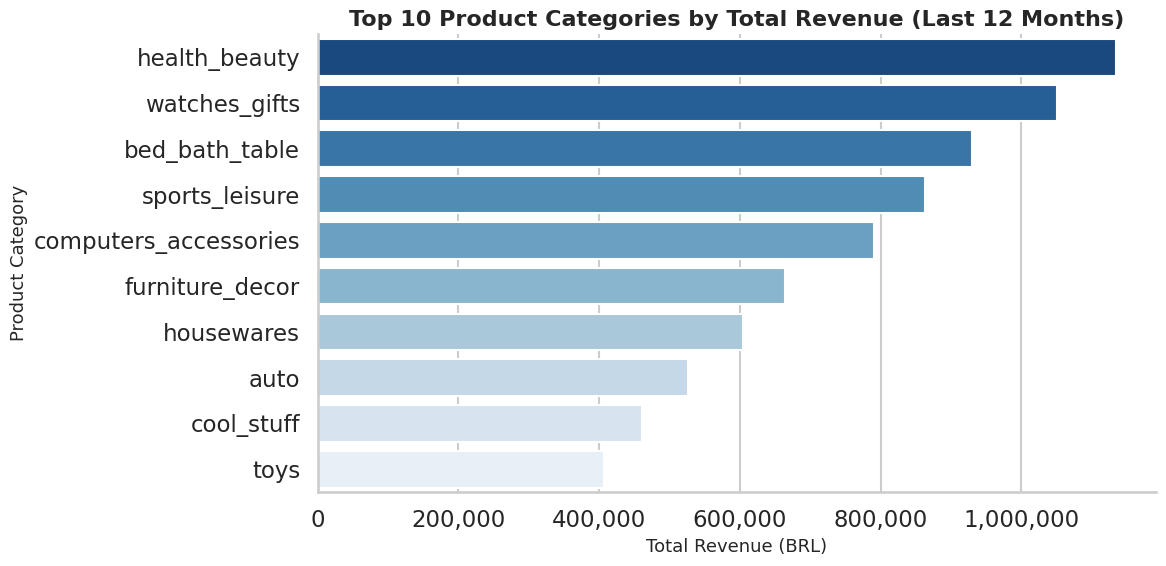

In [ ]:
# 1. Top 10 kategori berdasarkan total revenue
top10_sales = sales_by_category.sort_values(by='total_revenue', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top10_sales,
    y='product_category_name_english',
    x='total_revenue',
    hue='product_category_name_english',  # tambahkan hue agar kompatibel
    dodge=False,
    palette='Blues_r',
    legend=False
)
plt.title('Top 10 Product Categories by Total Revenue (Last 12 Months)', fontsize=16, weight='bold')
plt.xlabel('Total Revenue (BRL)', fontsize=13)
plt.ylabel('Product Category', fontsize=13)
plt.gca().xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.show()

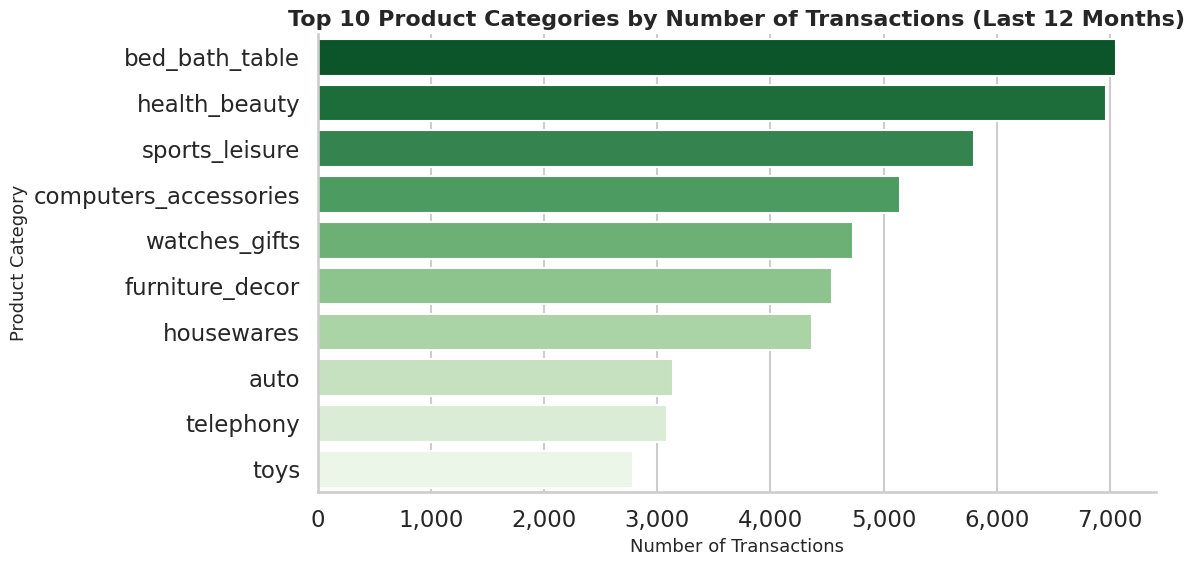

In [ ]:
# 2. Top 10 kategori berdasarkan total transaksi
top10_trans = sales_by_category.sort_values(by='total_transactions', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top10_trans,
    y='product_category_name_english',
    x='total_transactions',
    hue='product_category_name_english',
    dodge=False,
    palette='Greens_r',
    legend=False
)
plt.title('Top 10 Product Categories by Number of Transactions (Last 12 Months)', fontsize=16, weight='bold')
plt.xlabel('Number of Transactions', fontsize=13)
plt.ylabel('Product Category', fontsize=13)
plt.gca().xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# Unduh dataset
sales_by_category.to_csv('sales_by_category.csv', index=False)

**INSIGHT:**

- ***Top 10 Kategori Berdasarkan Total Revenue (12 Bulan Terakhir):***
Kategori health_beauty menjadi penyumbang pendapatan tertinggi perusahaan selama 12 bulan terakhir, diikuti oleh watches_gifts dan bed_bath_table. Kategori seperti health_beauty dan computers_accessories memiliki rata-rata nilai transaksi per order yang tinggi, menandakan produk dengan harga premium dan kontribusi besar terhadap total pendapatan meski frekuensi transaksinya tidak sebanyak kategori lain. Sementara kategori seperti sports_leisure dan furniture_decor tetap memberikan kontribusi signifikan, mencerminkan pasar yang stabil dan permintaan konsumen yang konsisten.

- ***Top 10 Kategori Berdasarkan Jumlah Transaksi (12 Bulan Terakhir):***
Kategori bed_bath_table dan health_beauty mendominasi jumlah transaksi, menunjukkan frekuensi pembelian tinggi dan tingkat permintaan yang berulang dari pelanggan. Kategori lain seperti sports_leisure, computers_accessories, dan watches_gifts juga memiliki volume transaksi besar, menandakan ketertarikan kuat terhadap produk gaya hidup dan teknologi. Sebaliknya, kategori seperti furniture_decor dan auto memiliki frekuensi pembelian lebih rendah meskipun nilainya besar, menggambarkan produk bernilai tinggi dengan siklus pembelian lebih panjang.

- ***Kesimpulan:***
Pola penjualan menunjukkan bahwa perusahaan mengandalkan kombinasi antara produk cepat laku dengan margin kecil dan produk premium dengan margin besar untuk menjaga stabilitas pendapatan. Produk kebutuhan rutin seperti bed_bath_table dan health_beauty menjadi pendorong utama volume penjualan, sedangkan produk bernilai tinggi seperti watches_gifts dan computers_accessories berperan penting dalam meningkatkan total pendapatan. Kombinasi ini mencerminkan strategi bisnis yang seimbang antara sustainabilitas penjualan jangka panjang dan profitabilitas tinggi per transaksi.

### Q2 Visualization and Explanatory Analysis

**Pertanyaan:**

*Siapa saja 10 seller dengan nilai transaksi tertinggi dan jumlah pesanan terbanyak selama 6 bulan terakhir, serta apakah terdapat korelasi antara frekuensi penjualan dan rata-rata skor ulasan yang diterima?*

**Tujuan Visualisasi dan Explanation Analysis:**
1. Menampilkan 10 seller dengan nilai transaksi tertinggi.
2. Menunjukkan apakah ada korelasi antara jumlah pesanan dan skor ulasan rata-rata (indikator hubungan antara produktivitas dan kualitas pelayanan).

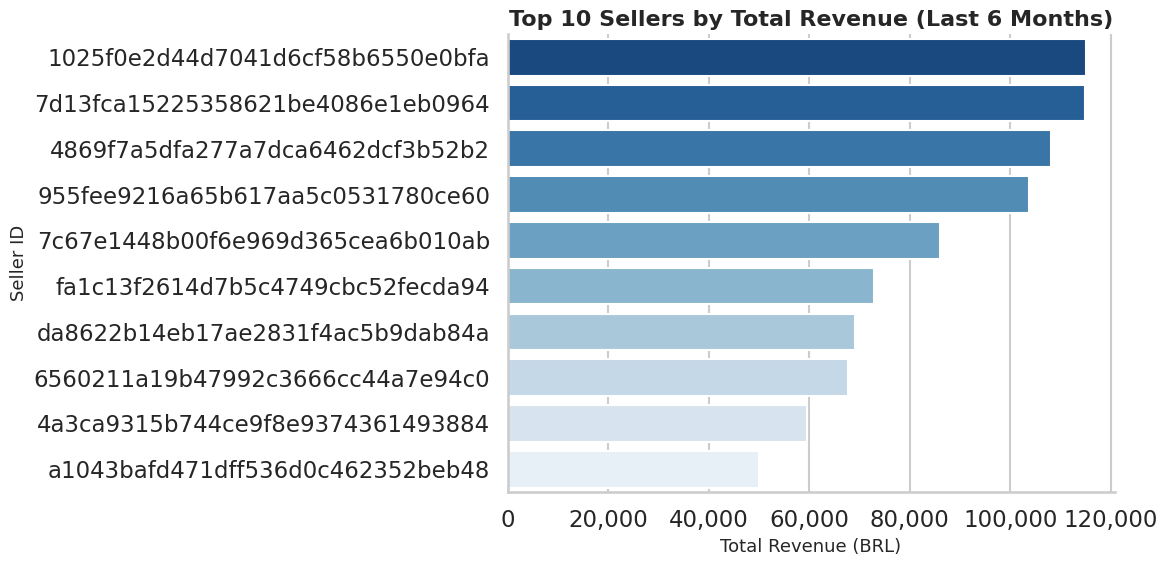

In [ ]:
# 1. Top 10 seller berdasarkan Total Revenue
top10_revenue = seller_summary.sort_values(by='total_revenue', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top10_revenue,
    y='seller_id',
    x='total_revenue',
    hue='seller_id',
    dodge=False,
    palette='Blues_r',
    legend=False
)
plt.title('Top 10 Sellers by Total Revenue (Last 6 Months)', fontsize=16, weight='bold')
plt.xlabel('Total Revenue (BRL)', fontsize=13)
plt.ylabel('Seller ID', fontsize=13)
plt.gca().xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.show()

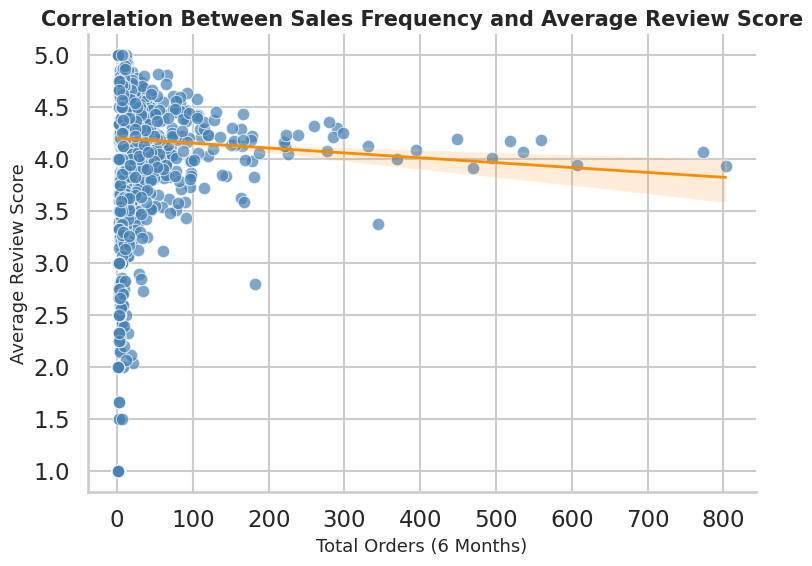

In [ ]:
# 2. Scatterplot Korelasi antara total_orders dan avg_review_score
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=seller_summary,
    x='total_orders',
    y='avg_review_score',
    alpha=0.7,
    color='steelblue'
)
sns.regplot(
    data=seller_summary,
    x='total_orders',
    y='avg_review_score',
    scatter=False,
    color='darkorange',
    line_kws={'lw': 2}
)
plt.title('Correlation Between Sales Frequency and Average Review Score', fontsize=15, weight='bold')
plt.xlabel('Total Orders (6 Months)', fontsize=13)
plt.ylabel('Average Review Score', fontsize=13)
plt.gca().xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# 3. Hitung korelasi
correlation = seller_summary['total_orders'].corr(seller_summary['avg_review_score'])
print(f"Korelasi antara frekuensi penjualan dan skor ulasan rata-rata: {correlation:.3f}")

Korelasi antara frekuensi penjualan dan skor ulasan rata-rata: -0.029


In [ ]:
# Unduh dataset
seller_summary.to_csv('seller_summary.csv', index=False)

**INSIGHT:**

- ***Top 10 Seller Berdasarkan Total Revenue (6 Bulan Terakhir):***
Seller dengan ID 1025f0e2d44d7041d6cf58b6550e0bfa mencatat total pendapatan tertinggi selama enam bulan terakhir dengan nilai transaksi mencapai sekitar 115 ribu BRL, diikuti oleh 7d13fca15225358621be4086e1eb0964 dan 4869f7a5dfa277a7dca6462dcf3b52b2. Penjual-penjual ini kemungkinan menjual produk dengan nilai unit tinggi atau volume besar dalam satu transaksi, sehingga mampu menghasilkan pendapatan tinggi meski jumlah pesanannya tidak selalu paling banyak.

- ***Top 10 Seller Berdasarkan Jumlah Pesanan (6 Bulan Terakhir):***
Seller 6560211a19b47992c3666cc44a7e94c0 menjadi penjual dengan jumlah pesanan terbanyak (803 order), diikuti oleh 955fee9216a65b617aa5c0531780ce60 dan 1025f0e2d44d7041d6cf58b6550e0bfa. Hal ini menunjukkan adanya perbedaan strategi antar penjual — sebagian berfokus pada volume transaksi besar dengan produk berharga terjangkau, sementara yang lain mengandalkan nilai transaksi tinggi per order untuk mencapai pendapatan maksimal. Pola ini mencerminkan keberagaman model bisnis penjual di platform perusahaan.

- ***Korelasi antara Frekuensi Penjualan dan Skor Ulasan Rata-rata:***
Hasil scatterplot menunjukkan korelasi sangat lemah (-0,029) antara jumlah pesanan dan skor ulasan rata-rata. Artinya, frekuensi penjualan tidak memiliki pengaruh signifikan terhadap tingkat kepuasan pelanggan. Baik penjual dengan volume tinggi maupun rendah cenderung mempertahankan skor ulasan yang relatif stabil di sekitar nilai 4, menandakan konsistensi kualitas layanan di seluruh tingkat aktivitas penjualan.

- ***Kesimpulan:***
Selama enam bulan terakhir, performa perusahaan ditopang oleh sekelompok penjual kunci yang berkontribusi besar terhadap pendapatan total. Meskipun terdapat variasi dalam strategi, antara penjual volume tinggi dan penjual bernilai tinggi, kualitas layanan secara keseluruhan tetap stabil. Hal ini menegaskan bahwa perusahaan memiliki ekosistem penjual yang kompetitif dan seimbang, di mana pertumbuhan penjualan tidak mengorbankan pengalaman pelanggan.

### Q3 Visualization and Explanatory Analysis

**Pertanyaan:**

*Metode pembayaran dan jumlah cicilan apa yang paling sering digunakan serta menghasilkan nilai transaksi tertinggi selama 12 bulan terakhir?*

**Tujuan Visualisasi dan Explanation Analysis:**
1. Metode pembayaran yang paling banyak digunakan dan kontribusinya terhadap nilai transaksi total.
2. Jumlah cicilan yang paling sering dipilih pelanggan.

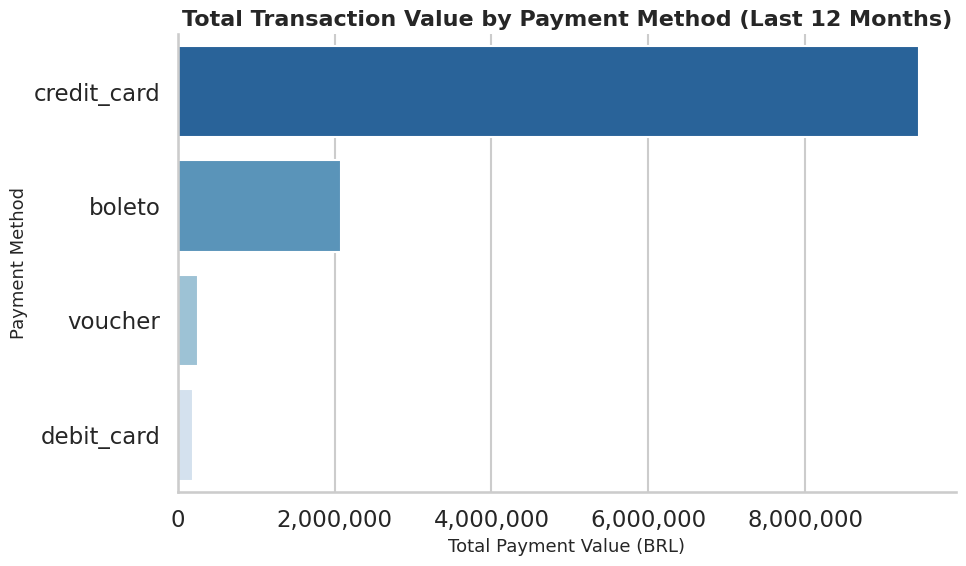

In [ ]:
# 1. Top metode pembayaran berdasarkan total nilai transaksi
payment_summary_sorted = payment_summary.sort_values(by='total_payment_value', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=payment_summary_sorted,
    y='payment_type',
    x='total_payment_value',
    hue='payment_type',
    dodge=False,
    palette='Blues_r',
    legend=False
)
plt.title('Total Transaction Value by Payment Method (Last 12 Months)', fontsize=16, weight='bold')
plt.xlabel('Total Payment Value (BRL)', fontsize=13)
plt.ylabel('Payment Method', fontsize=13)
plt.gca().xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.show()

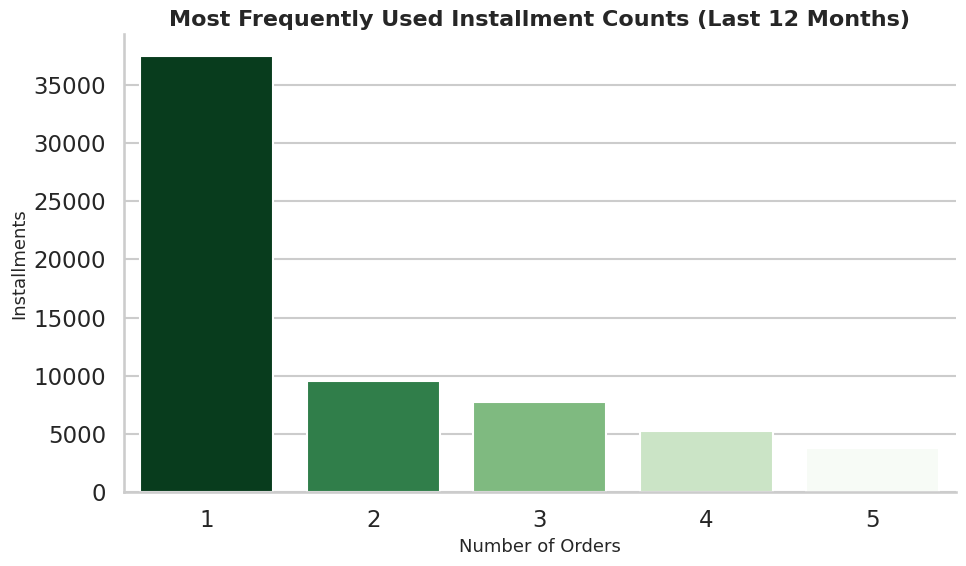

In [ ]:
# 2. Jumlah cicilan yang paling sering digunakan
installment_summary_sorted = installment_summary.sort_values(by='total_orders', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=installment_summary_sorted.head(),
    y='total_orders',
    x='payment_installments',
    hue='payment_installments',
    dodge=False,
    palette='Greens_r',
    legend=False
)
plt.title('Most Frequently Used Installment Counts (Last 12 Months)', fontsize=16, weight='bold')
plt.xlabel('Number of Orders', fontsize=13)
plt.ylabel('Installments', fontsize=13)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# Unduh dataset
payment_summary.to_csv('payment_summary.csv', index=False)
installment_summary.to_csv('installment_summary.csv', index=False)

**INSIGHT:**

- ***Total Nilai Transaksi Berdasarkan Metode Pembayaran (12 Bulan Terakhir):***
Grafik menunjukkan bahwa credit_card menjadi metode pembayaran yang paling dominan, dengan total nilai transaksi mencapai sekitar 9,45 juta BRL, jauh melampaui metode lain seperti boleto (sekitar 2,08 juta BRL). Metode pembayaran lain seperti voucher dan debit_card hanya menyumbang sebagian kecil dari total transaksi. Hal ini menunjukkan bahwa mayoritas pelanggan mengandalkan kartu kredit, baik untuk pembayaran langsung maupun sistem cicilan, karena dianggap paling mudah dan fleksibel.

- ***Jumlah Cicilan yang Paling Sering Digunakan (12 Bulan Terakhir):***
Dari sisi jumlah cicilan, pelanggan paling sering menggunakan 1 kali pembayaran (tanpa cicilan) dengan lebih dari 37.000 transaksi, diikuti oleh 2–3 kali cicilan dengan frekuensi yang jauh lebih kecil. Hal ini menandakan bahwa mayoritas pelanggan memilih pembayaran langsung untuk menyelesaikan transaksi mereka, sementara sebagian kecil memilih cicilan pendek untuk pembelian dengan nilai yang lebih besar. Pola ini menggambarkan bahwa pelanggan perusahaan lebih cenderung bertransaksi secara praktis dan cepat, dengan preferensi rendah terhadap pembayaran jangka panjang.

- ***Kesimpulan:***
Secara keseluruhan, analisis menunjukkan bahwa transaksi berbasis kartu kredit mendominasi sistem pembayaran perusahaan, baik melalui pembayaran penuh maupun cicilan pendek. Pelanggan umumnya memilih pembayaran langsung (1x cicilan) karena kemudahan dan efisiensinya, sementara cicilan 2–3 kali tetap populer di segmen transaksi bernilai tinggi. Pola ini menegaskan bahwa kartu kredit adalah motor utama pendapatan perusahaan, dan strategi bisnis yang memfasilitasi kemudahan pembayaran non-tunai menjadi faktor penting dalam mempertahankan loyalitas pelanggan.

### Q4 Visualization and Explanatory Analysis

**Pertanyaan:**

*Bagaimana distribusi skor ulasan pelanggan dan durasi respons terhadap ulasan per kategori produk selama 12 bulan terakhir, serta kategori mana yang memiliki tingkat kepuasan tertinggi dan terendah?*

**Tujuan Visualisasi dan Explanation Analysis:**
1. Kategori produk dengan skor ulasan rata-rata tertinggi (paling memuaskan).
2. Kategori produk dengan skor ulasan rata-rata terendah (perlu perbaikan).
3. Memberikan konteks tentang kecepatan respon terhadap ulasan pelanggan.

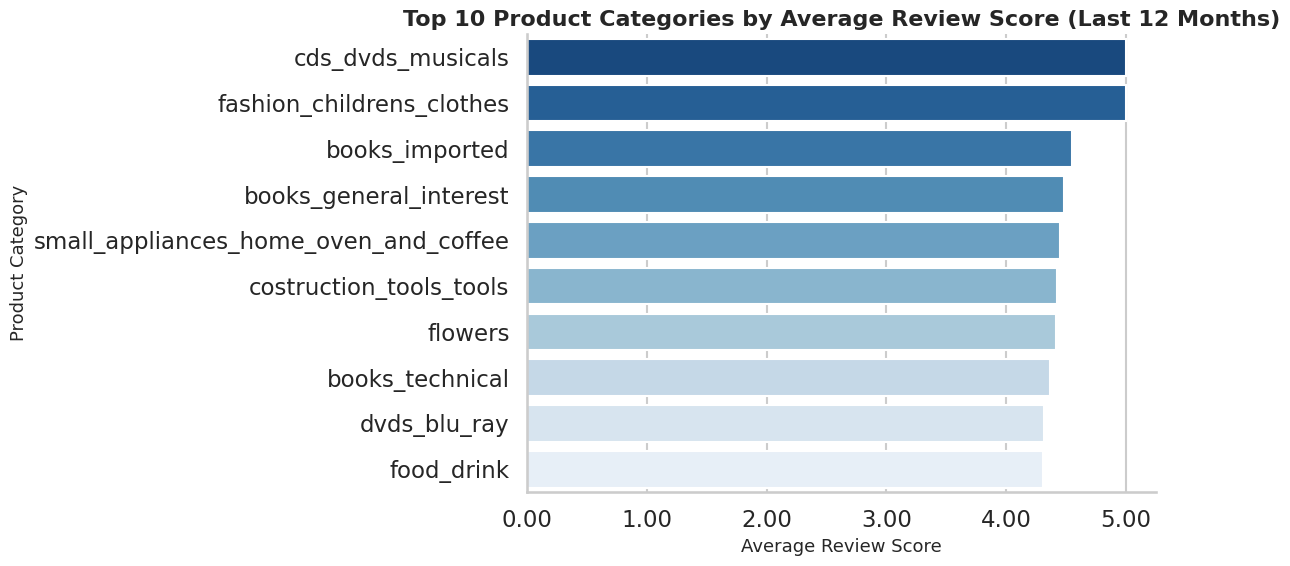

In [ ]:
# 1. Top 10 kategori dengan skor ulasan tertinggi
top10_highest = review_summary.sort_values(by='avg_review_score', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top10_highest,
    y='product_category_name_english',
    x='avg_review_score',
    hue='product_category_name_english',
    dodge=False,
    palette='Blues_r',
    legend=False
)
plt.title('Top 10 Product Categories by Average Review Score (Last 12 Months)', fontsize=16, weight='bold')
plt.xlabel('Average Review Score', fontsize=13)
plt.ylabel('Product Category', fontsize=13)
plt.gca().xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.2f}'))
sns.despine()
plt.tight_layout()
plt.show()

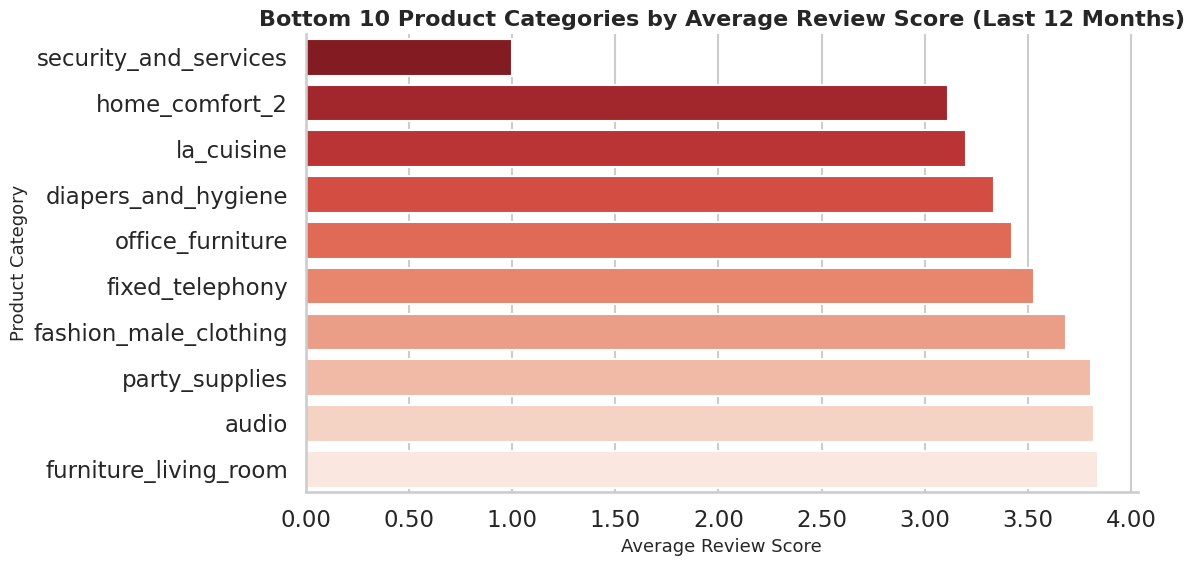

In [ ]:
# 2. Top 10 kategori dengan skor ulasan terendahtop10_lowest = review_summary.sort_values(by='avg_review_score', ascending=True).head(10)
top10_lowest = review_summary.sort_values(by='avg_review_score', ascending=True).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top10_lowest,
    y='product_category_name_english',
    x='avg_review_score',
    hue='product_category_name_english',
    dodge=False,
    palette='Reds_r',
    legend=False
)
plt.title('Bottom 10 Product Categories by Average Review Score (Last 12 Months)', fontsize=16, weight='bold')
plt.xlabel('Average Review Score', fontsize=13)
plt.ylabel('Product Category', fontsize=13)
plt.gca().xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:.2f}'))
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# Unduh dataset
review_summary.to_csv('review_summary.csv', index=False)

**INSIGHT:**

- ***10 Kategori Produk Teratas Berdasarkan Skor Ulasan Rata-Rata (12 Bulan Terakhir):***
Kategori cds_dvds_musicals dan fashion_childrens_clothes mencatat skor ulasan sempurna (5,00), menandakan tingkat kepuasan pelanggan yang sangat tinggi pada produk-produk hiburan dan pakaian anak. Kategori lain seperti books_imported (4,55) dan books_general_interest (4,48) juga menunjukkan performa unggul, mencerminkan kepuasan konsumen yang konsisten terhadap produk literasi dan media. Selain itu, kategori small_appliances_home_oven_and_coffee dan costruction_tools_tools menempati posisi menengah atas dengan skor sekitar 4,4–4,5, menunjukkan bahwa produk rumah tangga dan perkakas memiliki layanan purna jual yang baik dan kualitas produk yang sesuai harapan pelanggan.

- ***10 Kategori Produk Terbawah Berdasarkan Skor Ulasan Rata-Rata (12 Bulan Terakhir):***
Kategori security_and_services mencatat skor ulasan terendah (1,00), menunjukkan tingkat ketidakpuasan ekstrem meskipun volumenya kecil. Disusul oleh home_comfort_2 (3,11) dan la_cuisine (3,20), yang menunjukkan adanya masalah konsistensi kualitas atau pengalaman pelanggan yang tidak sesuai ekspektasi.
Kategori office_furniture (3,42) dan fixed_telephony (3,53) juga termasuk dalam kelompok bawah, menandakan tantangan pada kualitas produk dan layanan pengiriman. Sementara kategori seperti audio, furniture_living_room, dan party_supplies memiliki skor mendekati rata-rata, tetapi masih perlu perhatian untuk meningkatkan pengalaman pelanggan.

- ***Kesimpulan:***
Secara keseluruhan, rata-rata skor ulasan pelanggan berada pada level tinggi (4,04 dari 5), menunjukkan tingkat kepuasan yang kuat di sebagian besar kategori produk.
Kategori dengan skor tertinggi seperti buku, alat rumah tangga kecil, dan produk anak-anak menunjukkan bahwa kualitas produk dan layanan pelanggan di segmen ini sudah sangat baik. Namun, kategori dengan skor rendah, khususnya furniture dan produk elektronik, memerlukan peningkatan dalam kontrol kualitas, pengemasan, dan kecepatan respon terhadap ulasan negatif. Temuan ini menunjukkan bahwa perusahaan telah berhasil mempertahankan kepuasan pelanggan secara umum, tetapi masih memiliki ruang perbaikan signifikan pada kategori dengan skor ulasan rendah.

### Q5 Visualization and Explanatory Analysis

**Pertanyaan:**

*Bagaimana tren total penjualan dan jumlah pesanan perusahaan per bulan selama 18 bulan terakhir?*

**Tujuan Visualisasi dan Explanation Analysis:**
1. Apakah penjualan dan pesanan meningkat, menurun, atau stabil dari bulan ke bulan.
2. Apakah terdapat pola musiman (seasonal trends) seperti puncak di akhir tahun.
3. Kapan periode performa terbaik dan terlemah perusahaan terjadi.

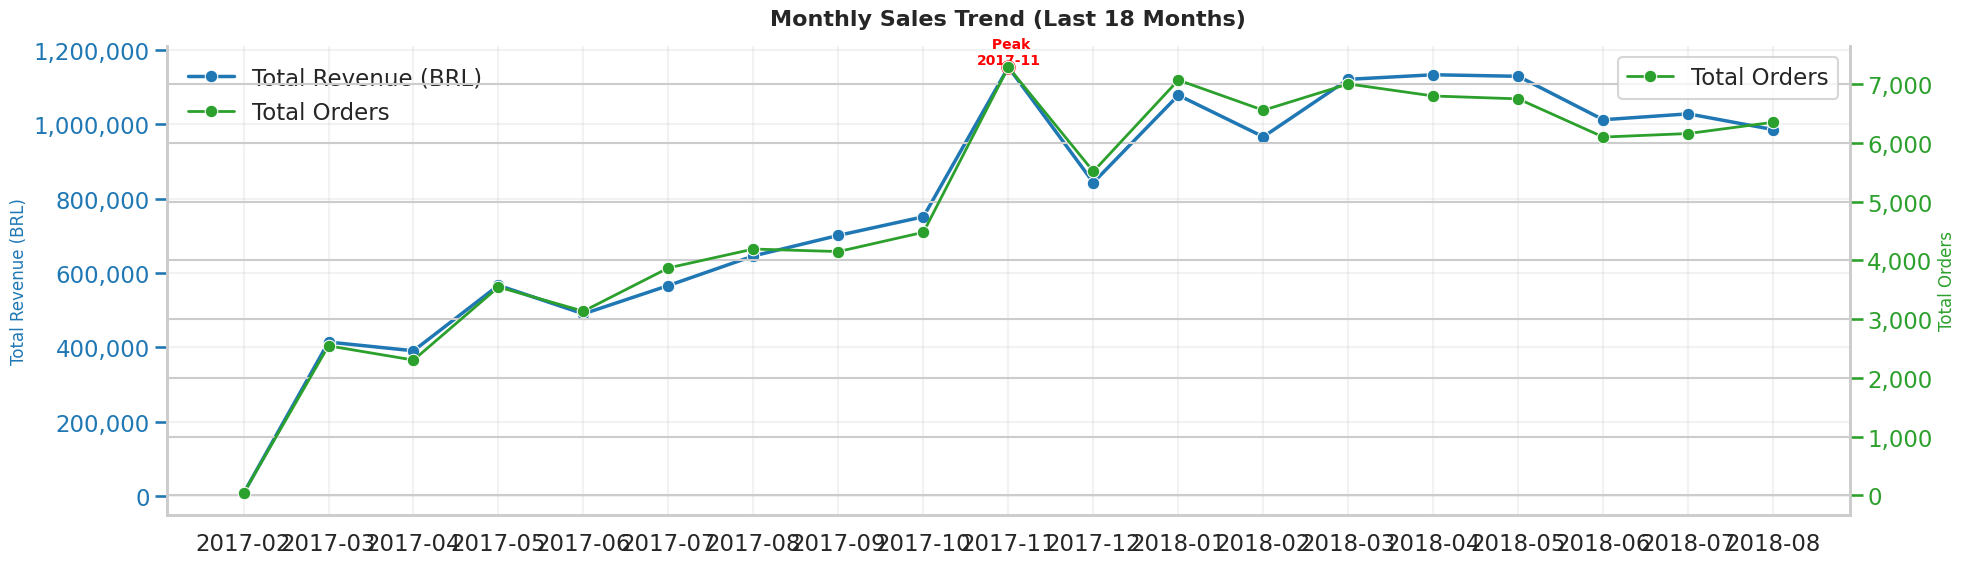

In [ ]:
fig, ax1 = plt.subplots(figsize=(20, 6))

color_revenue = '#1f77b4'
sns.lineplot(
    data=monthly_sales,
    x='order_month',
    y='total_revenue',
    color=color_revenue,
    linewidth=2.5,
    marker='o',
    ax=ax1,
    label='Total Revenue (BRL)'
)

ax2 = ax1.twinx()
color_orders = '#2ca02c'
sns.lineplot(
    data=monthly_sales,
    x='order_month',
    y='total_orders',
    color=color_orders,
    linewidth=2.0,
    marker='o',
    ax=ax2,
    label='Total Orders'
)

ax1.set_title(
    'Monthly Sales Trend (Last 18 Months)',
    fontsize=16,
    fontweight='bold',
    pad=15
)
ax1.set_xlabel('')
ax1.set_ylabel('Total Revenue (BRL)', color=color_revenue, fontsize=12)
ax2.set_ylabel('Total Orders', color=color_orders, fontsize=12)
ax1.tick_params(axis='y', colors=color_revenue)
ax2.tick_params(axis='y', colors=color_orders)
ax1.grid(alpha=0.25)

ax1.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax2.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))

peak = monthly_sales.loc[monthly_sales['total_revenue'].idxmax()]
ax1.scatter(
    peak['order_month'],
    peak['total_revenue'],
    color='red',
    s=80,
    zorder=5
)
ax1.text(
    peak['order_month'],
    peak['total_revenue'],
    f" Peak\n{peak['order_month']}",
    color='red',
    fontsize=10,
    fontweight='bold',
    ha='center',
    va='bottom'
)

lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left', frameon=False)

sns.despine(right=False)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# Unduh dataset
monthly_sales.to_csv('monthly_sales.csv', index=False)

**INSIGHT:**

- ***Tren Pendapatan Total & Pesanan (18 Bulan Terakhir)***
Tren penjualan menunjukkan pertumbuhan yang konsisten dan signifikan selama 18 bulan terakhir. Pada awal periode (akhir 2016 hingga awal 2017), volume pesanan dan pendapatan masih rendah, di bawah 200.000 BRL per bulan, menandakan fase awal ekspansi bisnis. Memasuki pertengahan 2017, penjualan mulai menunjukkan momentum positif, meningkat stabil hingga mencapai puncaknya pada November 2017, dengan nilai transaksi total sekitar 1,15 juta BRL dan lebih dari 7.000 pesanan. Lonjakan ini kemungkinan besar dipengaruhi oleh musim promosi akhir tahun (Black Friday) atau strategi pemasaran besar-besaran yang meningkatkan aktivitas belanja pelanggan secara signifikan. Setelah puncak tersebut, performa perusahaan tetap stabil di level tinggi sepanjang paruh pertama tahun 2018.
Total pendapatan bulanan tetap berada di kisaran 900.000–1.000.000 BRL, dengan volume pesanan yang sebanding, menunjukkan daya beli pelanggan yang kuat dan loyalitas yang terjaga.

### Q6 Visualization and Explanatory Analysis (RFM Customer Segmentation)

**Pertanyaan:**

*Bagaimana segmentasi pelanggan berdasarkan analisis RFM (Recency, Frequency, Monetary), segmen mana yang memberikan kontribusi pendapatan terbesar, dan apa rekomendasi strategi bisnis yang relevan untuk setiap segmen?*

**Tujuan Visualisasi dan Explanatory Analysis:**
1. Memvisualisasikan distribusi jumlah pelanggan di setiap segmen RFM untuk memahami komposisi basis pengguna.
2. Membandingkan kontribusi pendapatan (total monetary) antar segmen untuk mengidentifikasi segmen yang paling bernilai bagi bisnis.
3. Menampilkan profil rata-rata metrik Recency, Frequency, dan Monetary per segmen untuk merumuskan aksi bisnis yang presisi.
4. Menyimpan data agregat rfm_summary.csv untuk visualisasi interaktif pada dashboard Streamlit.


In [ ]:
# 1. Barplot Distribusi Jumlah Pelanggan per Segmen
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=rfm_summary.sort_values('customer_count', ascending=False),
    y='segment',
    x='customer_count',
    hue='segment',
    dodge=False,
    palette='Blues_r',
    legend=False,
    ax=ax
)
ax.set_title('Customer Distribution by RFM Segment', fontsize=14, weight='bold')
ax.set_xlabel('Number of Customers', fontsize=11)
ax.set_ylabel('')
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.show()

# 2. Barplot Kontribusi Total Pendapatan per Segmen
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=rfm_summary.sort_values('total_monetary', ascending=False),
    y='segment',
    x='total_monetary',
    hue='segment',
    dodge=False,
    palette='Greens_r',
    legend=False,
    ax=ax
)
ax.set_title('Total Revenue Contribution by RFM Segment (BRL)', fontsize=14, weight='bold')
ax.set_xlabel('Total Monetary Value (BRL)', fontsize=11)
ax.set_ylabel('')
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
sns.despine()
plt.tight_layout()
plt.show()


In [ ]:
# 3. Profil Rata-Rata Recency, Frequency, dan Monetary Antar Segmen
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(
    data=rfm_summary, x='segment', y='avg_recency',
    hue='segment', dodge=False, palette='Blues_r', legend=False, ax=axes[0]
)
axes[0].set_title('Average Recency (Days)', fontsize=12, weight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Days')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    data=rfm_summary, x='segment', y='avg_frequency',
    hue='segment', dodge=False, palette='Greens_r', legend=False, ax=axes[1]
)
axes[1].set_title('Average Frequency (Orders)', fontsize=12, weight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of Orders')
axes[1].tick_params(axis='x', rotation=45)

sns.barplot(
    data=rfm_summary, x='segment', y='avg_monetary',
    hue='segment', dodge=False, palette='Purples_r', legend=False, ax=axes[2]
)
axes[2].set_title('Average Monetary (BRL)', fontsize=12, weight='bold')
axes[2].set_xlabel('')
axes[2].set_ylabel('Average Spend (BRL)')
axes[2].tick_params(axis='x', rotation=45)

sns.despine()
plt.tight_layout()
plt.show()


In [ ]:
# Unduh dataset agregat RFM
rfm_summary.to_csv('rfm_summary.csv', index=False)
rfm_summary.to_csv('dashboard/rfm_summary.csv', index=False)


**INSIGHT:**

Visualisasi RFM memperlihatkan dinamika portofolio pelanggan perusahaan:

1. **Distribusi Volume vs Nilai (Volume vs Value Discrepancy):**
   Segmen Hibernating dan New Customers mencakup hampir separuh populasi pelanggan (47,4%), namun hanya menyumbang ~20,9% pendapatan. Sebaliknya, segmen Potential Loyalists dan At Risk hanya mencakup 31,3% pelanggan namun mengendalikan lebih dari 57,6% pendapatan total (8,88 juta BRL).

2. **Rekomendasi Aksi Bisnis Berbasis Data (Actionable Roadmap):**
   - **Potential Loyalists (Target Konversi Utama):** Berikan voucher diskon untuk pembelian kedua yang dibatasi waktu (30 hari sejak transaksi pertama) serta rekomendasi produk komplementer. Meningkatkan konversi repeat order sebesar 5% pada segmen ini akan memberikan lonjakan revenue signifikan.
   - **At Risk (Target Penyelamatan Pendapatan):** Jalankan kampanye *win-back* terpersonalisasi melalui email atau promosi kupon eksklusif bernilai besar untuk mengaktifkan kembali pembeli bernilai tinggi yang mulai dorman.
   - **Champions & Loyal Customers (Target Retensi & Advokasi):** Sediakan program loyalitas VIP, early-access untuk produk baru, dan layanan pelanggan prioritas untuk menjaga kepuasan prima.
   - **New Customers (Target Onboarding):** Kirimkan rangkaian pesan *welcome email*, panduan penggunaan platform, dan insentif ulasan produk pertama.
   - **Hibernating (Efisiensi Biaya):** Hindari biaya retargeting iklan berbayar yang mahal pada kelompok ini. Cukup kirimkan *newsletter* promosi berkala berbiaya rendah.


## Conclusion

Selama periode analisis, data menunjukkan performa bisnis perusahaan yang kuat dan stabil di berbagai aspek, mulai dari distribusi kategori produk hingga pola perilaku pelanggan. Enam pertanyaan utama dijawab melalui analisis data penjualan, kinerja penjual, metode pembayaran, kepuasan pelanggan, dan tren waktu untuk menggambarkan dinamika pertumbuhan bisnis secara menyeluruh.

1. ***Conclusion Analisis Penjualan per Kategori Produk:*** Selama 12 bulan terakhir, kategori health_beauty, watches_gifts, dan bed_bath_table menjadi penyumbang pendapatan tertinggi, dengan total revenue mencapai lebih dari 1 juta BRL untuk kategori teratas. Dari sisi volume transaksi, bed_bath_table dan health_beauty mencatat jumlah pesanan tertinggi, menunjukkan permintaan yang tinggi dan berulang dari pelanggan. Pola ini menegaskan bahwa perusahaan mengandalkan kombinasi antara produk cepat laku dengan margin kecil dan produk premium bernilai tinggi, yang menciptakan stabilitas pendapatan sekaligus profitabilitas jangka panjang.

2. ***Conclution Analisis Kinerja Penjual:*** Dalam enam bulan terakhir, penjual 1025f0e2d44d7041d6cf58b6550e0bfa mencatat pendapatan tertinggi (±115.000 BRL), sementara 6560211a19b47992c3666cc44a7e94c0 menjadi penjual dengan jumlah pesanan terbanyak (803 order). Analisis korelasi menunjukkan nilai -0.029 antara frekuensi penjualan dan skor ulasan rata-rata, artinya jumlah pesanan tidak berpengaruh signifikan terhadap tingkat kepuasan pelanggan. Temuan ini menunjukkan bahwa kualitas layanan penjual konsisten di berbagai skala bisnis, dan perusahaan memiliki basis penjual yang kompetitif dan stabil.

3. ***Conclution Analisis Metode Pembayaran:*** Metode pembayaran credit_card mendominasi transaksi perusahaan dengan nilai lebih dari 9,45 juta BRL, jauh melampaui boleto (2,08 juta BRL) dan metode lainnya. Sebagian besar pelanggan memilih pembayaran langsung (1x cicilan) dengan lebih dari 37.000 transaksi, diikuti oleh 2–3 kali cicilan untuk transaksi bernilai lebih tinggi. Pola ini menunjukkan bahwa pelanggan cenderung mengutamakan kenyamanan dan fleksibilitas kartu kredit, sekaligus menegaskan bahwa transaksi berbasis kredit adalah motor utama pendapatan perusahaan.

4. ***Conclution Analisis Kepuasan Pelanggan:*** Rata-rata skor ulasan pelanggan mencapai 4,04 dari 5, menandakan tingkat kepuasan tinggi secara keseluruhan. Kategori cds_dvds_musicals, fashion_childrens_clothes, dan books_imported mencatat skor tertinggi (≥4,5), mencerminkan kepuasan pelanggan terhadap produk media dan pakaian anak. Sebaliknya, kategori seperti security_and_services, office_furniture, dan fixed_telephony memperoleh skor rendah (≤3,5), menunjukkan tantangan pada kualitas produk dan pengalaman layanan. Secara umum, pelanggan menilai positif aspek pengiriman dan kualitas barang, namun peningkatan layanan purna jual dan kecepatan respon masih diperlukan di kategori tertentu.

5. ***Conclution Analisis Tren Penjualan Bulanan:*** Selama 18 bulan terakhir, penjualan menunjukkan pertumbuhan yang konsisten, dengan peningkatan signifikan sejak awal 2017 hingga mencapai puncak pada November 2017 (sekitar 1,15 juta BRL dan 7.000 pesanan). Puncak ini kemungkinan besar dipicu oleh promosi akhir tahun seperti Black Friday dan kegiatan pemasaran besar-besaran. Setelah puncak, penjualan tetap stabil di level tinggi hingga pertengahan 2018, mencerminkan loyalitas pelanggan yang kuat dan strategi retensi yang efektif.
Tren ini menegaskan bahwa kampanye musiman memberikan dampak besar terhadap performa tahunan, sementara stabilitas setelah puncak menunjukkan kesehatan bisnis jangka panjang.



6. ***Conclusion Segmentasi Pelanggan (RFM Analysis):*** Analisis RFM pada 93.358 pelanggan unik menunjukkan bahwa 97% pelanggan melakukan transaksi tunggal (single purchase), karakteristik umum marketplace produk tahan lama (durable goods). Dua segmen yang menjadi penopang pendapatan terbesar adalah **Potential Loyalists** (15,48% pelanggan, kontribusi 28,31% revenue atau 4,37 juta BRL) dan **At Risk** (15,77% pelanggan, kontribusi 29,30% revenue atau 4,52 juta BRL). Peluang pertumbuhan terbesar terletak pada konversi segmen Potential Loyalists menjadi pembeli berulang melalui voucher 30 hari pasca pembelian pertama, serta kampanye win-back terfokus untuk menyelamatkan segmen At Risk dari risiko churn permanen.

Analisis ini memperlihatkan bahwa perusahaan memiliki fundamental bisnis yang solid, dengan pertumbuhan positif di hampir semua dimensi:
- Produk dengan kontribusi pendapatan besar berasal dari kategori personal care, gifts, dan home essentials,
- Kinerja penjual dan kualitas layanan relatif seimbang di berbagai skala aktivitas,
- Transaksi berbasis kartu kredit menjadi penggerak utama ekonomi platform,
- Kepuasan pelanggan tinggi namun memerlukan peningkatan di kategori berisiko rendah,
- Tren penjualan jangka panjang menunjukkan stabilitas dan momentum pertumbuhan sehat.

Secara keseluruhan, perusahaan telah menunjukkan performa yang kuat dan berkelanjutan, dengan potensi optimalisasi pada strategi promosi musiman, peningkatan pengalaman pelanggan, dan perluasan kategori produk bernilai tinggi.